# Phase 3A Step 8 — Comprehensive Bivariate Analysis

## Customer Retention Intelligence System

This independent notebook examines two-variable relationships in the development split:

1. numerical predictors versus the categorical churn target;
2. categorical predictors versus the churn target;
3. pairs of numerical predictors; and
4. selected categorical–numerical business relationships.

The analysis is descriptive. Observed differences are not called statistically
significant, causally effective, or equivalent to model feature importance. No p-values,
formal association/correlation coefficients, multivariate interactions, transformations,
feature selection, balancing, or predictive models are used.

## 1. Independent setup and leakage-safe loading

The project root is found dynamically. Configuration is loaded through the existing
`retention.utils.config.load_config` utility, and the configured input is asserted to be
the development Parquet artifact before it is read. Neither earlier notebook must be run
first.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Find the nearest parent containing project markers.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "params.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

packages = ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "pyarrow"]
print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
print(f"Configured random state (unchanged): {config['project']['random_state']}")
for package in packages:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
Configured random state (unchanged): 42
pandas: 2.3.3
numpy: 2.4.6
matplotlib: 3.11.2
seaborn: 0.13.2
scipy: 1.17.1
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 250)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

df = pd.read_parquet(development_path)
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]

numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
    "Contract",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaymentMethod",
]
target_order = ["No", "Yes"]
target_colors = {"No": "#4C78A8", "Yes": "#E45756"}

assert set(df[target_column].unique()) == set(target_order)
assert target_column not in numerical_features + categorical_features
assert identifier_column not in numerical_features + categorical_features
overall_churn_rate = df[target_column].eq("Yes").mean()
total_churned = int(df[target_column].eq("Yes").sum())

print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Overall churn rate: {overall_churn_rate:.2%}")
display(df.head())

Development data: 5,634 rows × 21 columns
Overall churn rate: 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.100,"5,475.900",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.350,212.300,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.450,137.100,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.750,"2,453.300",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.000,"1,164.050",No


# 2. Numerical predictors versus churn

For a numerical feature $X$, group-wise summaries compare $X\mid Churn=Yes$ with
$X\mid Churn=No$. The signed mean contrast is

$$\Delta_{mean}=\bar X_{Yes}-\bar X_{No},$$

and the median contrast is $\Delta_{median}=\widetilde X_{Yes}-\widetilde X_{No}$.
Absolute mean difference describes magnitude but discards direction. Quartiles, IQR,
percentiles, variance, and standard deviation show spread and overlap.

These are sample descriptions. A difference may reflect confounding, selection, or
measurement structure; it is not a significance test, causal effect, or guarantee of
predictive value. The exact mode is reported only for discrete tenure because finely
measured monetary modes are unstable and rarely represent a meaningful typical value.

In [3]:
# ruff: noqa: E501
numeric_group_rows = []
for feature in numerical_features:
    for churn_class in target_order:
        series = df.loc[df[target_column].eq(churn_class), feature]
        quantiles = series.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
        numeric_group_rows.append({
            "feature": feature,
            "Churn": churn_class,
            "customer_count": len(series),
            "mean": series.mean(),
            "median": series.median(),
            "mode_if_meaningful": series.mode().iloc[0] if feature == "tenure" else np.nan,
            "standard_deviation": series.std(ddof=1),
            "sample_variance": series.var(ddof=1),
            "p10": quantiles.loc[0.10],
            "q1_p25": quantiles.loc[0.25],
            "q2_p50": quantiles.loc[0.50],
            "q3_p75": quantiles.loc[0.75],
            "p90": quantiles.loc[0.90],
            "IQR": quantiles.loc[0.75] - quantiles.loc[0.25],
            "skewness": series.skew(),
        })

numeric_group_profile = pd.DataFrame(numeric_group_rows).set_index(["feature", "Churn"])

numeric_difference_rows = []
for feature in numerical_features:
    no_values = df.loc[df[target_column].eq("No"), feature]
    yes_values = df.loc[df[target_column].eq("Yes"), feature]
    numeric_difference_rows.append({
        "feature": feature,
        "retained_mean": no_values.mean(),
        "churned_mean": yes_values.mean(),
        "signed_mean_difference_yes_minus_no": yes_values.mean() - no_values.mean(),
        "absolute_mean_difference": abs(yes_values.mean() - no_values.mean()),
        "retained_median": no_values.median(),
        "churned_median": yes_values.median(),
        "median_difference_yes_minus_no": yes_values.median() - no_values.median(),
    })
numeric_difference_summary = pd.DataFrame(numeric_difference_rows).set_index("feature")

display(numeric_group_profile)
display(Markdown("**Central-tendency contrasts**"))
display(numeric_difference_summary)

customer_count      mean    median  mode_if_meaningful  \
feature        Churn                                                           
tenure         No               4139    37.549    37.000              72.000   
               Yes              1495    17.955    10.000               1.000   
MonthlyCharges No               4139    61.625    64.900                 NaN   
               Yes              1495    74.468    79.600                 NaN   
TotalCharges   No               4139 2,566.501 1,683.600                 NaN   
               Yes              1495 1,529.879   712.750                 NaN   

                      standard_deviation  sample_variance     p10  q1_p25  \
feature        Churn                                                        
tenure         No                 24.144          582.939   4.000  15.000   
               Yes                19.536          381.661   1.000   2.000   
MonthlyCharges No                 31.084          966.220  19.900  25.200   
               Yes                24.519          601.177  35.090  56.675   
TotalCharges   No              2,342.991    5,489,606.641 154.500 579.550   
               Yes             1,885.864    3,556,482.220  59.910 130.900   

                        q2_p50    q3_p75       p90       IQR  skewness  
feature        Churn                                                    
tenure         No       37.000    61.000    71.000    46.000    -0.031  
               Yes      10.000    29.000    50.000    27.000     1.151  
MonthlyCharges No       64.900    88.775   103.200    63.575    -0.041  
               Yes      79.600    94.200   101.350    37.525    -0.742  
TotalCharges   No    1,683.600 4,300.200 6,326.280 3,720.650     0.804  
               Yes     712.750 2,343.700 4,511.330 2,212.800     1.513

**Central-tendency contrasts**

,retained_mean,churned_mean,signed_mean_difference_yes_minus_no,absolute_mean_difference,retained_median,churned_median,median_difference_yes_minus_no
feature,,,,,,,
tenure,37.549,17.955,-19.594,19.594,37.000,10.000,-27.000
MonthlyCharges,61.625,74.468,12.843,12.843,64.900,79.600,14.700
TotalCharges,"2,566.501","1,529.879","-1,036.623","1,036.623","1,683.600",712.750,-970.850


In [4]:
# ruff: noqa: E501
display(Markdown(
    "### Observed numerical contrasts\n\n"
    f"- **Tenure:** churned customers average {numeric_difference_summary.loc['tenure', 'churned_mean']:.2f} "
    f"months versus {numeric_difference_summary.loc['tenure', 'retained_mean']:.2f} for retained customers. "
    f"The signed mean difference is {numeric_difference_summary.loc['tenure', 'signed_mean_difference_yes_minus_no']:.2f} "
    f"months and the median difference is {numeric_difference_summary.loc['tenure', 'median_difference_yes_minus_no']:.0f}. "
    "The churned distribution is right-skewed and concentrated earlier in the lifecycle, but substantial overlap remains.\n"
    f"- **MonthlyCharges:** churned customers average {numeric_difference_summary.loc['MonthlyCharges', 'churned_mean']:.2f} "
    f"versus {numeric_difference_summary.loc['MonthlyCharges', 'retained_mean']:.2f}; the mean contrast is "
    f"+{numeric_difference_summary.loc['MonthlyCharges', 'signed_mean_difference_yes_minus_no']:.2f} and the median contrast "
    f"is +{numeric_difference_summary.loc['MonthlyCharges', 'median_difference_yes_minus_no']:.2f}. Both groups span broad, "
    "overlapping price ranges, so monthly charge alone cannot separate outcomes.\n"
    f"- **TotalCharges:** churned customers average {numeric_difference_summary.loc['TotalCharges', 'churned_mean']:.2f} "
    f"versus {numeric_difference_summary.loc['TotalCharges', 'retained_mean']:.2f}; the signed mean contrast is "
    f"{numeric_difference_summary.loc['TotalCharges', 'signed_mean_difference_yes_minus_no']:.2f}. Lower churned totals are "
    "compatible with their shorter tenure, illustrating why a marginal charge contrast can be confounded by lifecycle."
))

### Observed numerical contrasts

- **Tenure:** churned customers average 17.96 months versus 37.55 for retained customers. The signed mean difference is -19.59 months and the median difference is -27. The churned distribution is right-skewed and concentrated earlier in the lifecycle, but substantial overlap remains.
- **MonthlyCharges:** churned customers average 74.47 versus 61.62; the mean contrast is +12.84 and the median contrast is +14.70. Both groups span broad, overlapping price ranges, so monthly charge alone cannot separate outcomes.
- **TotalCharges:** churned customers average 1529.88 versus 2566.50; the signed mean contrast is -1036.62. Lower churned totals are compatible with their shorter tenure, illustrating why a marginal charge contrast can be confounded by lifecycle.

## 2.1 Grouped box and violin plots

Box plots compare medians, IQRs, and conventional $1.5\times IQR$ whiskers. Violin plots
add smoothed within-group density. They reveal overlap and dispersion but do not establish
significance. Violin width is a density estimate—not the number of customers—and KDE
smoothing is approximate for discrete tenure.

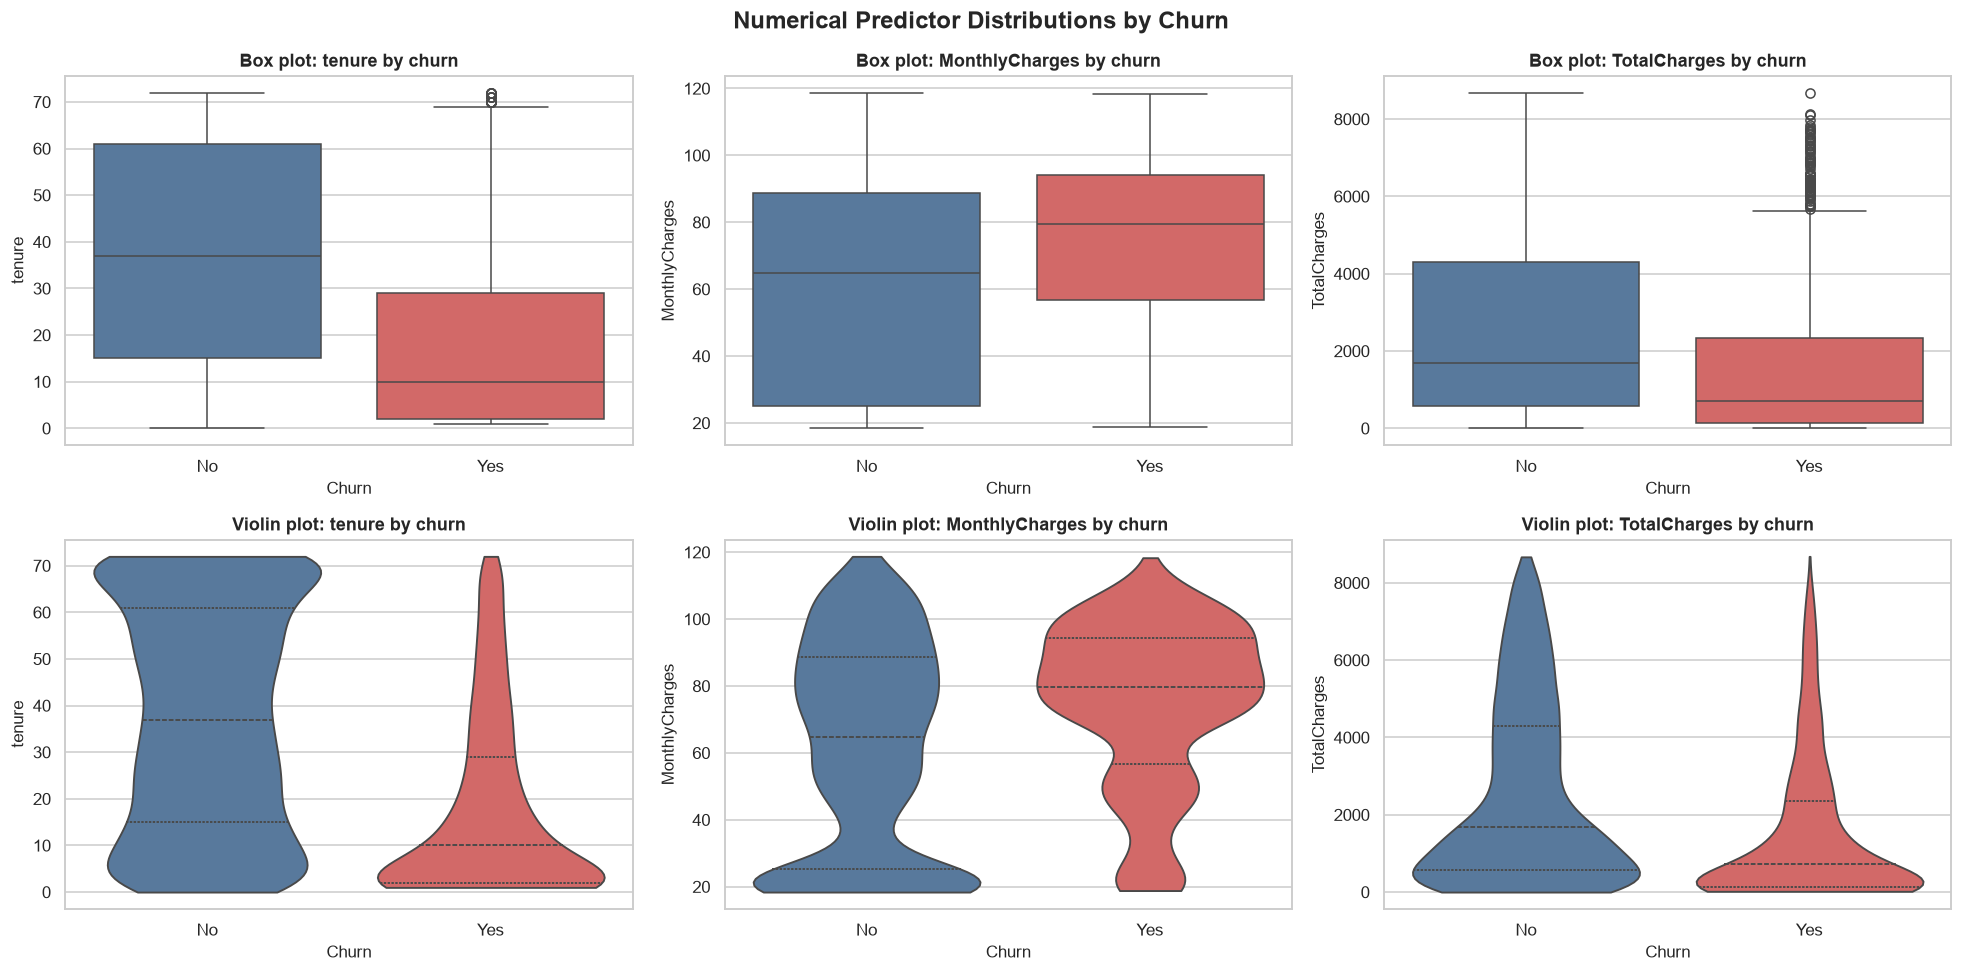

In [5]:
# ruff: noqa: E501
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for feature, box_axis, violin_axis in zip(
    numerical_features,
    axes[0],
    axes[1],
    strict=True,
):
    sns.boxplot(
        data=df,
        x=target_column,
        y=feature,
        order=target_order,
        hue=target_column,
        palette=target_colors,
        legend=False,
        ax=box_axis,
    )
    box_axis.set(title=f"Box plot: {feature} by churn", xlabel="Churn")
    sns.violinplot(
        data=df,
        x=target_column,
        y=feature,
        order=target_order,
        hue=target_column,
        palette=target_colors,
        legend=False,
        inner="quartile",
        cut=0,
        ax=violin_axis,
    )
    violin_axis.set(title=f"Violin plot: {feature} by churn", xlabel="Churn")

fig.suptitle("Numerical Predictor Distributions by Churn", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

## 2.2 Normalized histograms and KDE

Unequal class sizes make raw histogram counts misleading. Each overlaid histogram is
normalized to density within its class (`common_norm=False`), so shape rather than volume
is compared. KDE is shown separately for continuous charges; it is omitted for discrete,
bounded tenure because smoothing can imply impossible fractional months and values outside
the valid range. Density curves can conceal local spikes and depend on bandwidth.

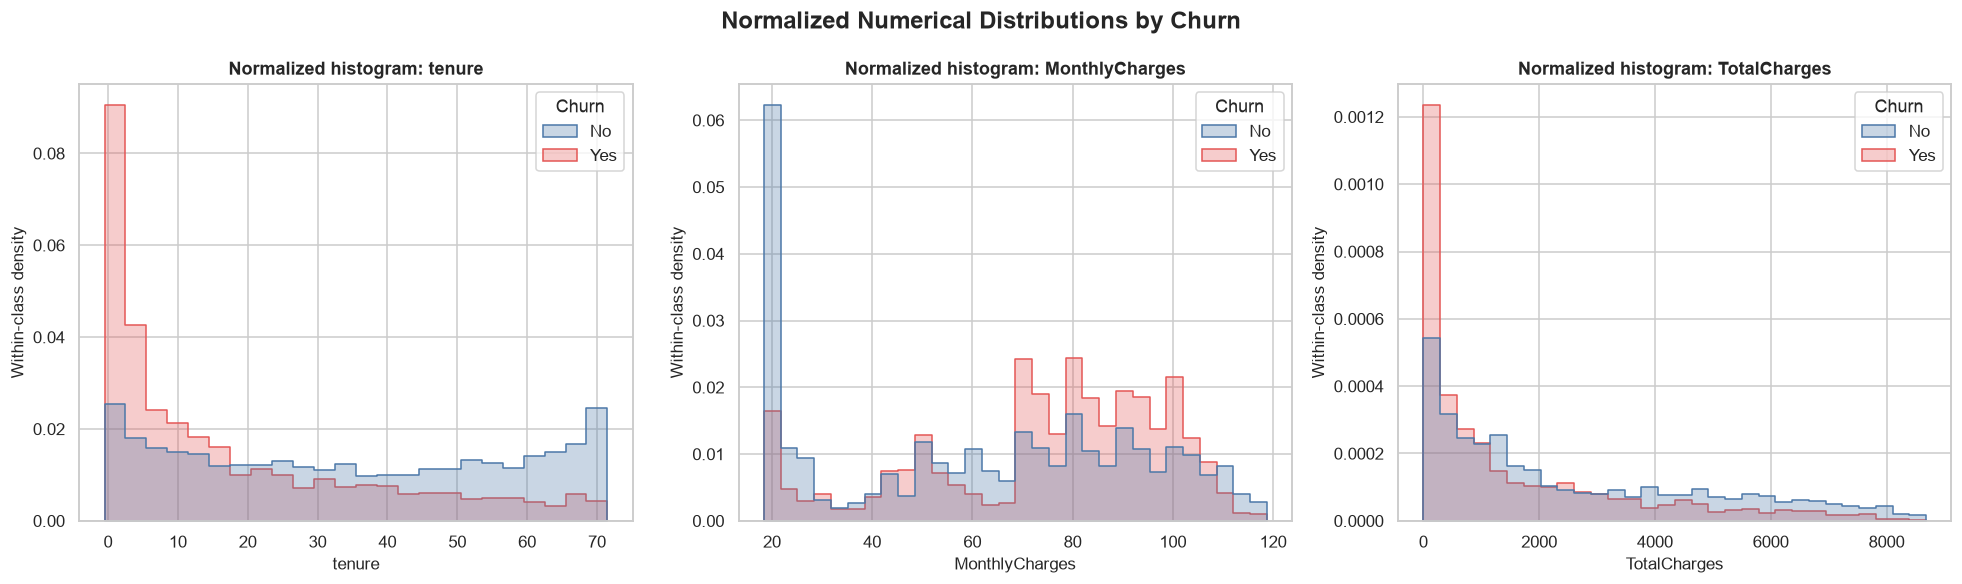

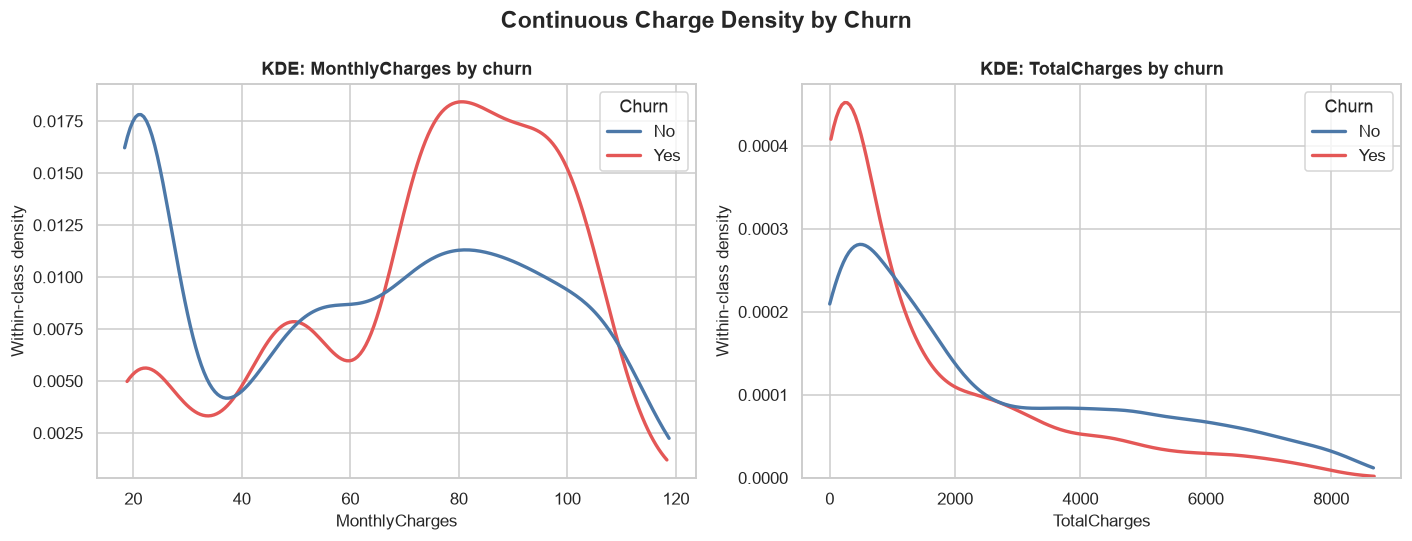

In [6]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
hist_bins = {
    "tenure": np.arange(-0.5, 73.5, 3),
    "MonthlyCharges": 30,
    "TotalCharges": 30,
}
for axis, feature in zip(axes, numerical_features, strict=True):
    sns.histplot(
        data=df,
        x=feature,
        hue=target_column,
        hue_order=target_order,
        palette=target_colors,
        bins=hist_bins[feature],
        stat="density",
        common_norm=False,
        element="step",
        alpha=0.30,
        ax=axis,
    )
    axis.set(title=f"Normalized histogram: {feature}", ylabel="Within-class density")
fig.suptitle("Normalized Numerical Distributions by Churn", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, feature in zip(axes, ["MonthlyCharges", "TotalCharges"], strict=True):
    sns.kdeplot(
        data=df,
        x=feature,
        hue=target_column,
        hue_order=target_order,
        palette=target_colors,
        common_norm=False,
        fill=False,
        linewidth=2.2,
        cut=0,
        ax=axis,
    )
    axis.set(title=f"KDE: {feature} by churn", ylabel="Within-class density")
fig.suptitle("Continuous Charge Density by Churn", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

## 2.3 Group-wise ECDFs and distribution overlap

For group $g$, the empirical CDF is

$$\widehat F_g(x)=\frac{1}{n_g}\sum_{i\in g}\mathbf{1}(x_i\le x).$$

Vertical separation between curves indicates different cumulative distributions at that
value; crossing curves shows that ordering changes across the range. ECDFs display all
observations without bins or bandwidth but do not quantify significance.

Overlap is operationally important: even where group centres differ, overlapping values
mean a single threshold will create false positives and false negatives. Predictive
relevance must later be evaluated jointly and out of sample.

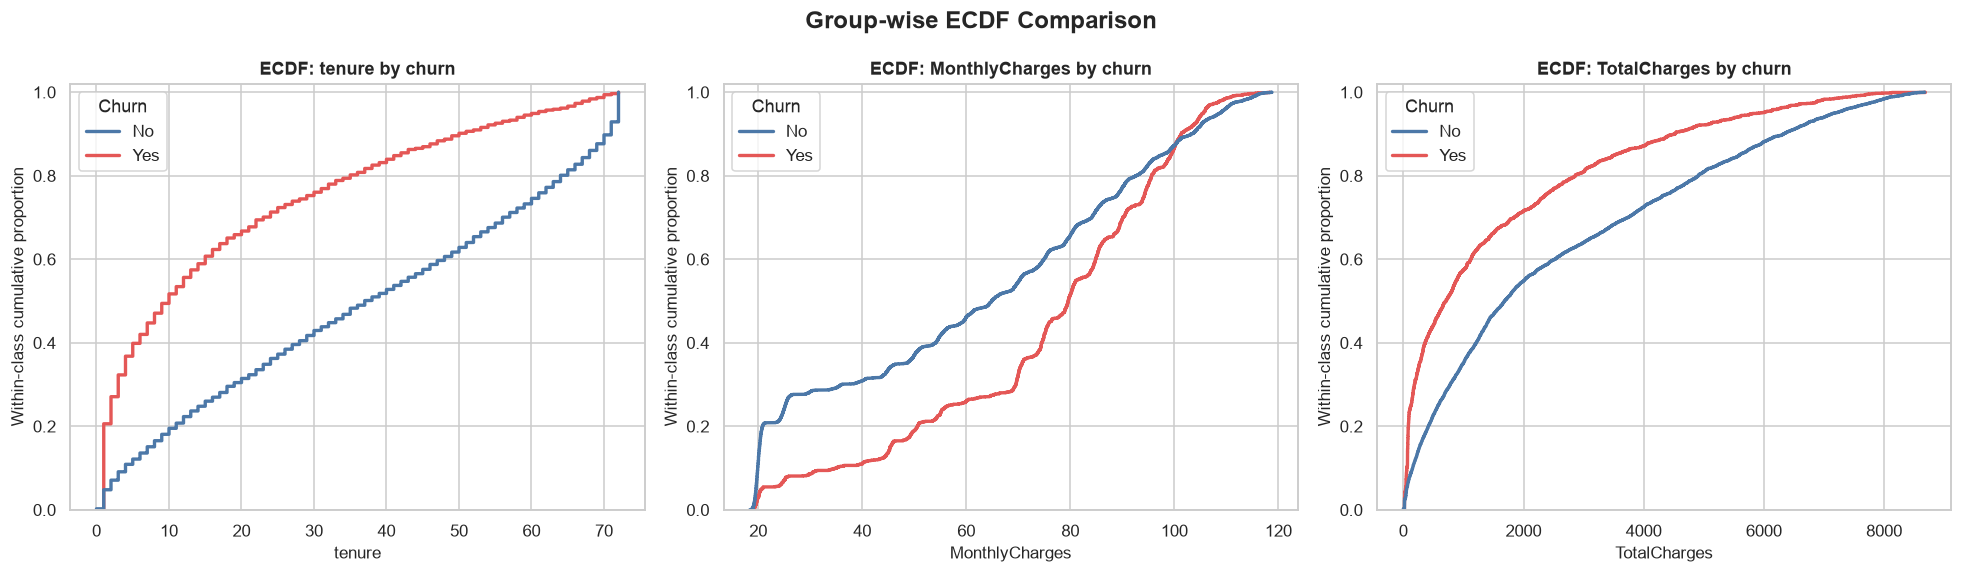

In [7]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
for axis, feature in zip(axes, numerical_features, strict=True):
    sns.ecdfplot(
        data=df,
        x=feature,
        hue=target_column,
        hue_order=target_order,
        palette=target_colors,
        linewidth=2.2,
        ax=axis,
    )
    axis.set(
        title=f"ECDF: {feature} by churn",
        ylabel="Within-class cumulative proportion",
        ylim=(0, 1.02),
    )
fig.suptitle("Group-wise ECDF Comparison", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

# 3. Categorical predictors versus churn

## 3.1 Contingency tables and conditional probability

A contingency table contains joint counts $n_{c,y}$ for category $c$ and target state $y$.
Three normalizations answer different questions:

$$P(Churn=y\mid Category=c)=\frac{n_{c,y}}{n_c}$$

is a **row-normalized** category-specific outcome rate;

$$P(Category=c\mid Churn=y)=\frac{n_{c,y}}{n_y}$$

is **column-normalized** and describes the composition of an outcome group; and

$$P(Churn=y,Category=c)=\frac{n_{c,y}}{n}$$

is the joint population share. Reversing a conditional changes the denominator and the
business question.

Percentage-point difference is

$$\Delta_{pp}=100\,[P(Yes\mid c)-P(Yes)],$$

while relative churn rate is $P(Yes\mid c)/P(Yes)$. A +10 percentage-point difference is
an absolute change; a ratio of 1.5 means the observed category rate is 50% above the
overall rate. Neither is a causal effect or significance test.

In [8]:
# ruff: noqa: E501
contingency_counts = {}
row_normalized = {}
column_normalized = {}
joint_probabilities = {}
consolidated_rows = []

for feature in categorical_features:
    counts = pd.crosstab(df[feature], df[target_column]).reindex(columns=target_order, fill_value=0)
    row_pct = pd.crosstab(df[feature], df[target_column], normalize="index").reindex(columns=target_order, fill_value=0)
    column_pct = pd.crosstab(df[feature], df[target_column], normalize="columns").reindex(columns=target_order, fill_value=0)
    joint = pd.crosstab(df[feature], df[target_column], normalize="all").reindex(columns=target_order, fill_value=0)
    contingency_counts[feature] = counts
    row_normalized[feature] = row_pct
    column_normalized[feature] = column_pct
    joint_probabilities[feature] = joint

    for category in counts.index:
        retained = int(counts.loc[category, "No"])
        churned = int(counts.loc[category, "Yes"])
        total = retained + churned
        churn_rate = churned / total
        consolidated_rows.append({
            "feature": feature,
            "category": str(category),
            "total_customers": total,
            "churned_customers": churned,
            "retained_customers": retained,
            "category_churn_rate": churn_rate,
            "category_retention_rate": retained / total,
            "overall_churn_rate": overall_churn_rate,
            "percentage_point_difference": (churn_rate - overall_churn_rate) * 100,
            "relative_churn_rate": churn_rate / overall_churn_rate,
            "share_of_all_churned_customers": churned / total_churned,
            "joint_probability_churn_and_category": churned / len(df),
            "category_share_within_churned": column_pct.loc[category, "Yes"],
        })

category_churn_profile = pd.DataFrame(consolidated_rows)

def combine_tables(table_dictionary: dict[str, pd.DataFrame]) -> pd.DataFrame:
    return pd.concat(table_dictionary, names=["feature", "category"])


display(Markdown("**Absolute contingency counts**"))
display(combine_tables(contingency_counts))
display(Markdown("**Row-normalized probabilities: P(Churn | Category)**"))
display(combine_tables(row_normalized))
display(Markdown("**Column-normalized probabilities: P(Category | Churn)**"))
display(combine_tables(column_normalized))
display(Markdown("**Joint probabilities: P(Category, Churn)**"))
display(combine_tables(joint_probabilities))

**Absolute contingency counts**

Churn                                         No   Yes
feature          category                             
gender           Female                     2017   755
                 Male                       2122   740
SeniorCitizen    0                          3612  1114
                 1                           527   381
Partner          No                         1968   968
                 Yes                        2171   527
Dependents       No                         2702  1222
                 Yes                        1437   273
PhoneService     No                          395   134
                 Yes                        3744  1361
PaperlessBilling No                         1902   367
                 Yes                        2237  1128
Contract         Month-to-month             1769  1326
                 One year                   1048   130
                 Two year                   1322    39
MultipleLines    No                         2052   678
                 No phone service            395   134
                 Yes                        1692   683
InternetService  DSL                        1566   368
                 Fiber optic                1456  1037
                 No                         1117    90
OnlineSecurity   No                         1649  1167
                 No internet service        1117    90
                 Yes                        1373   238
OnlineBackup     No                         1485   989
                 No internet service        1117    90
                 Yes                        1537   416
DeviceProtection No                         1525   973
                 No internet service        1117    90
                 Yes                        1497   432
TechSupport      No                         1623  1163
                 No internet service        1117    90
                 Yes                        1399   242
StreamingTV      No                         1490   740
                 No internet service        1117    90
                 Yes                        1532   665
StreamingMovies  No                         1466   758
                 No internet service        1117    90
                 Yes                        1556   647
PaymentMethod    Bank transfer (automatic)  1046   200
                 Credit card (automatic)    1025   190
                 Electronic check           1022   855
                 Mailed check               1046   250

**Row-normalized probabilities: P(Churn | Category)**

Churn                                         No   Yes
feature          category                             
gender           Female                    0.728 0.272
                 Male                      0.741 0.259
SeniorCitizen    0                         0.764 0.236
                 1                         0.580 0.420
Partner          No                        0.670 0.330
                 Yes                       0.805 0.195
Dependents       No                        0.689 0.311
                 Yes                       0.840 0.160
PhoneService     No                        0.747 0.253
                 Yes                       0.733 0.267
PaperlessBilling No                        0.838 0.162
                 Yes                       0.665 0.335
Contract         Month-to-month            0.572 0.428
                 One year                  0.890 0.110
                 Two year                  0.971 0.029
MultipleLines    No                        0.752 0.248
                 No phone service          0.747 0.253
                 Yes                       0.712 0.288
InternetService  DSL                       0.810 0.190
                 Fiber optic               0.584 0.416
                 No                        0.925 0.075
OnlineSecurity   No                        0.586 0.414
                 No internet service       0.925 0.075
                 Yes                       0.852 0.148
OnlineBackup     No                        0.600 0.400
                 No internet service       0.925 0.075
                 Yes                       0.787 0.213
DeviceProtection No                        0.610 0.390
                 No internet service       0.925 0.075
                 Yes                       0.776 0.224
TechSupport      No                        0.583 0.417
                 No internet service       0.925 0.075
                 Yes                       0.853 0.147
StreamingTV      No                        0.668 0.332
                 No internet service       0.925 0.075
                 Yes                       0.697 0.303
StreamingMovies  No                        0.659 0.341
                 No internet service       0.925 0.075
                 Yes                       0.706 0.294
PaymentMethod    Bank transfer (automatic) 0.839 0.161
                 Credit card (automatic)   0.844 0.156
                 Electronic check          0.544 0.456
                 Mailed check              0.807 0.193

**Column-normalized probabilities: P(Category | Churn)**

Churn                                         No   Yes
feature          category                             
gender           Female                    0.487 0.505
                 Male                      0.513 0.495
SeniorCitizen    0                         0.873 0.745
                 1                         0.127 0.255
Partner          No                        0.475 0.647
                 Yes                       0.525 0.353
Dependents       No                        0.653 0.817
                 Yes                       0.347 0.183
PhoneService     No                        0.095 0.090
                 Yes                       0.905 0.910
PaperlessBilling No                        0.460 0.245
                 Yes                       0.540 0.755
Contract         Month-to-month            0.427 0.887
                 One year                  0.253 0.087
                 Two year                  0.319 0.026
MultipleLines    No                        0.496 0.454
                 No phone service          0.095 0.090
                 Yes                       0.409 0.457
InternetService  DSL                       0.378 0.246
                 Fiber optic               0.352 0.694
                 No                        0.270 0.060
OnlineSecurity   No                        0.398 0.781
                 No internet service       0.270 0.060
                 Yes                       0.332 0.159
OnlineBackup     No                        0.359 0.662
                 No internet service       0.270 0.060
                 Yes                       0.371 0.278
DeviceProtection No                        0.368 0.651
                 No internet service       0.270 0.060
                 Yes                       0.362 0.289
TechSupport      No                        0.392 0.778
                 No internet service       0.270 0.060
                 Yes                       0.338 0.162
StreamingTV      No                        0.360 0.495
                 No internet service       0.270 0.060
                 Yes                       0.370 0.445
StreamingMovies  No                        0.354 0.507
                 No internet service       0.270 0.060
                 Yes                       0.376 0.433
PaymentMethod    Bank transfer (automatic) 0.253 0.134
                 Credit card (automatic)   0.248 0.127
                 Electronic check          0.247 0.572
                 Mailed check              0.253 0.167

**Joint probabilities: P(Category, Churn)**

Churn                                         No   Yes
feature          category                             
gender           Female                    0.358 0.134
                 Male                      0.377 0.131
SeniorCitizen    0                         0.641 0.198
                 1                         0.094 0.068
Partner          No                        0.349 0.172
                 Yes                       0.385 0.094
Dependents       No                        0.480 0.217
                 Yes                       0.255 0.048
PhoneService     No                        0.070 0.024
                 Yes                       0.665 0.242
PaperlessBilling No                        0.338 0.065
                 Yes                       0.397 0.200
Contract         Month-to-month            0.314 0.235
                 One year                  0.186 0.023
                 Two year                  0.235 0.007
MultipleLines    No                        0.364 0.120
                 No phone service          0.070 0.024
                 Yes                       0.300 0.121
InternetService  DSL                       0.278 0.065
                 Fiber optic               0.258 0.184
                 No                        0.198 0.016
OnlineSecurity   No                        0.293 0.207
                 No internet service       0.198 0.016
                 Yes                       0.244 0.042
OnlineBackup     No                        0.264 0.176
                 No internet service       0.198 0.016
                 Yes                       0.273 0.074
DeviceProtection No                        0.271 0.173
                 No internet service       0.198 0.016
                 Yes                       0.266 0.077
TechSupport      No                        0.288 0.206
                 No internet service       0.198 0.016
                 Yes                       0.248 0.043
StreamingTV      No                        0.264 0.131
                 No internet service       0.198 0.016
                 Yes                       0.272 0.118
StreamingMovies  No                        0.260 0.135
                 No internet service       0.198 0.016
                 Yes                       0.276 0.115
PaymentMethod    Bank transfer (automatic) 0.186 0.035
                 Credit card (automatic)   0.182 0.034
                 Electronic check          0.181 0.152
                 Mailed check              0.186 0.044

## 3.2 Consolidated churn-rate comparison

Rate and volume answer different questions. A high category churn rate means a large
fraction of that category churned. High absolute churn volume means many churners came from
that category, which may simply be very large. Rankings must display denominators: a high
rate from a small category is less operationally stable than the same rate from thousands
of customers.

The ranking below is descriptive, not feature importance. Categories from the same feature
are mutually exclusive, while categories from different features overlap in customers and
must not be added together.

In [9]:
# ruff: noqa: E501
category_churn_ranking = category_churn_profile.sort_values(
    ["category_churn_rate", "total_customers"],
    ascending=[False, False],
).reset_index(drop=True)
category_volume_ranking = category_churn_profile.sort_values(
    ["churned_customers", "category_churn_rate"],
    ascending=[False, False],
).reset_index(drop=True)

display(Markdown("**All categories ranked by observed churn rate**"))
display(category_churn_ranking)
display(Markdown("**Top 15 categories by absolute churn volume**"))
display(category_volume_ranking.head(15))

highest_rate = category_churn_ranking.iloc[0]
lowest_rate = category_churn_ranking.iloc[-1]
highest_volume = category_volume_ranking.iloc[0]
display(Markdown(
    f"**Observed extremes:** `{highest_rate['feature']} = {highest_rate['category']}` has the highest "
    f"rate at {highest_rate['category_churn_rate']:.2%} "
    f"({int(highest_rate['churned_customers']):,}/{int(highest_rate['total_customers']):,}). "
    f"`{lowest_rate['feature']} = {lowest_rate['category']}` has the lowest rate at "
    f"{lowest_rate['category_churn_rate']:.2%} "
    f"({int(lowest_rate['churned_customers']):,}/{int(lowest_rate['total_customers']):,}). "
    f"The largest absolute churn volume is `{highest_volume['feature']} = {highest_volume['category']}` "
    f"with {int(highest_volume['churned_customers']):,} churners, but its "
    f"{highest_volume['category_churn_rate']:.2%} rate is near the overall rate because that category "
    "contains most customers."
))

**All categories ranked by observed churn rate**

,feature,category,total_customers,churned_customers,retained_customers,category_churn_rate,category_retention_rate,overall_churn_rate,percentage_point_difference,relative_churn_rate,share_of_all_churned_customers,joint_probability_churn_and_category,category_share_within_churned
0,PaymentMethod,Electronic check,1877,855,1022,0.456,0.544,0.265,19.016,1.717,0.572,0.152,0.572
1,Contract,Month-to-month,3095,1326,1769,0.428,0.572,0.265,16.308,1.615,0.887,0.235,0.887
2,SeniorCitizen,1,908,381,527,0.420,0.580,0.265,15.425,1.581,0.255,0.068,0.255
3,TechSupport,No,2786,1163,1623,0.417,0.583,0.265,15.209,1.573,0.778,0.206,0.778
4,InternetService,Fiber optic,2493,1037,1456,0.416,0.584,0.265,15.061,1.568,0.694,0.184,0.694
5,OnlineSecurity,No,2816,1167,1649,0.414,0.586,0.265,14.906,1.562,0.781,0.207,0.781
6,OnlineBackup,No,2474,989,1485,0.400,0.600,0.265,13.440,1.507,0.662,0.176,0.662
7,DeviceProtection,No,2498,973,1525,0.390,0.610,0.265,12.416,1.468,0.651,0.173,0.651
8,StreamingMovies,No,2224,758,1466,0.341,0.659,0.265,7.547,1.284,0.507,0.135,0.507
9,PaperlessBilling,Yes,3365,1128,2237,0.335,0.665,0.265,6.986,1.263,0.755,0.200,0.755


**Top 15 categories by absolute churn volume**

,feature,category,total_customers,churned_customers,retained_customers,category_churn_rate,category_retention_rate,overall_churn_rate,percentage_point_difference,relative_churn_rate,share_of_all_churned_customers,joint_probability_churn_and_category,category_share_within_churned
0,PhoneService,Yes,5105,1361,3744,0.267,0.733,0.265,0.125,1.005,0.910,0.242,0.910
1,Contract,Month-to-month,3095,1326,1769,0.428,0.572,0.265,16.308,1.615,0.887,0.235,0.887
2,Dependents,No,3924,1222,2702,0.311,0.689,0.265,4.606,1.174,0.817,0.217,0.817
3,OnlineSecurity,No,2816,1167,1649,0.414,0.586,0.265,14.906,1.562,0.781,0.207,0.781
4,TechSupport,No,2786,1163,1623,0.417,0.583,0.265,15.209,1.573,0.778,0.206,0.778
5,PaperlessBilling,Yes,3365,1128,2237,0.335,0.665,0.265,6.986,1.263,0.755,0.200,0.755
6,SeniorCitizen,0,4726,1114,3612,0.236,0.764,0.265,-2.964,0.888,0.745,0.198,0.745
7,InternetService,Fiber optic,2493,1037,1456,0.416,0.584,0.265,15.061,1.568,0.694,0.184,0.694
8,OnlineBackup,No,2474,989,1485,0.400,0.600,0.265,13.440,1.507,0.662,0.176,0.662
9,DeviceProtection,No,2498,973,1525,0.390,0.610,0.265,12.416,1.468,0.651,0.173,0.651


**Observed extremes:** `PaymentMethod = Electronic check` has the highest rate at 45.55% (855/1,877). `Contract = Two year` has the lowest rate at 2.87% (39/1,361). The largest absolute churn volume is `PhoneService = Yes` with 1,361 churners, but its 26.66% rate is near the overall rate because that category contains most customers.

## 3.3 Business-dimension categorical visualizations

For every feature, three panels are shown:

1. grouped absolute retained/churned counts, annotated with customer volumes;
2. a 100% stacked bar representing $P(Churn\mid Category)$;
3. category churn rate with the overall 26.54% reference line and category sample size.

Structural states (`No internet service`, `No phone service`) remain separate from ordinary
`No`. The panels show association only and do not adjust for tenure, charges, contract, or
other potential confounders.

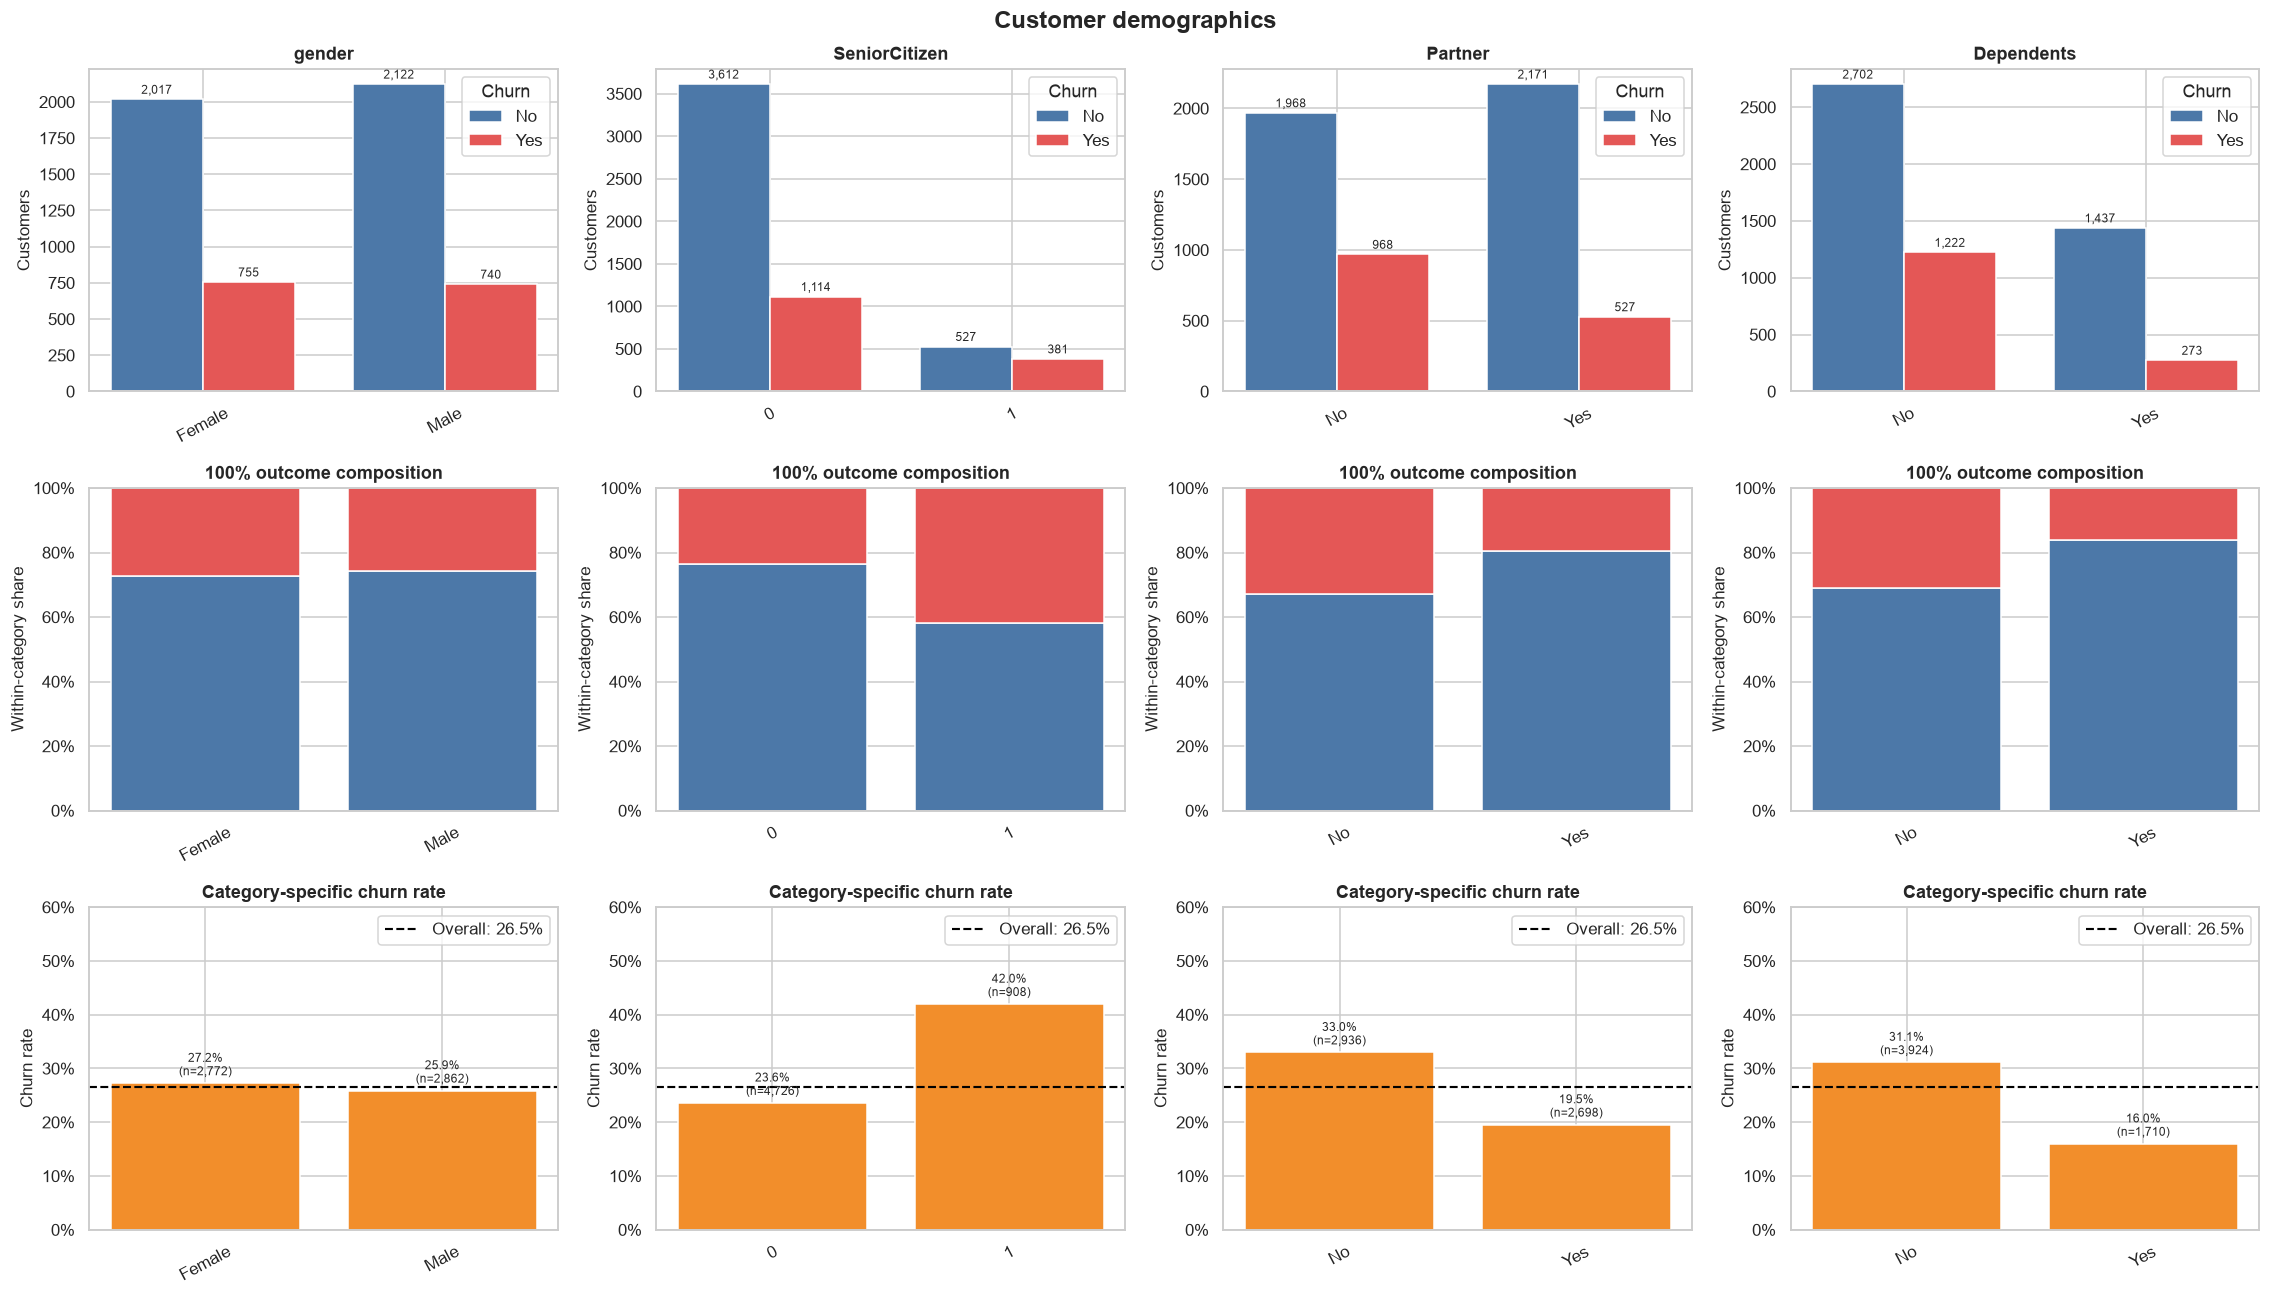

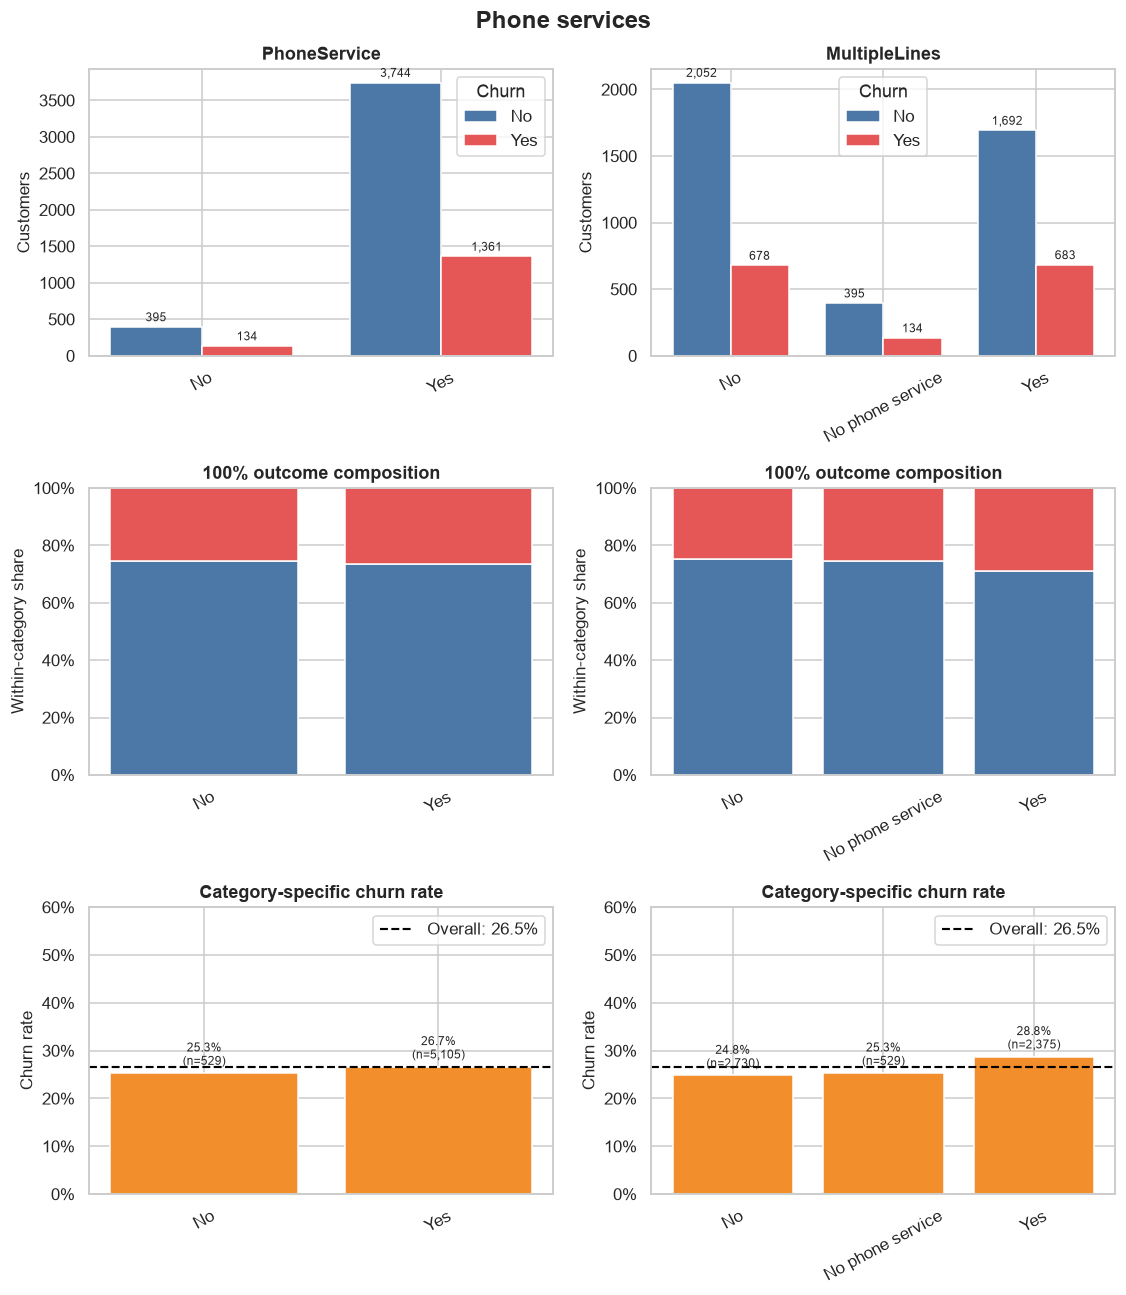

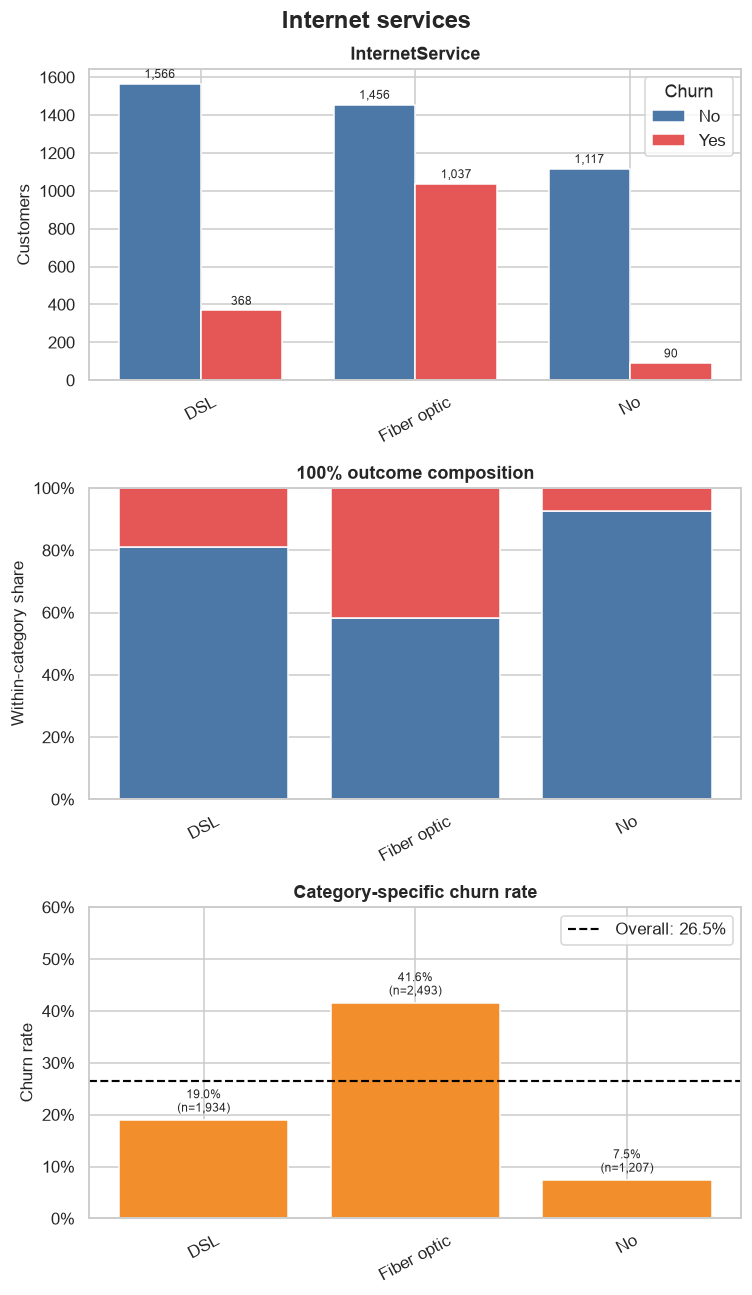

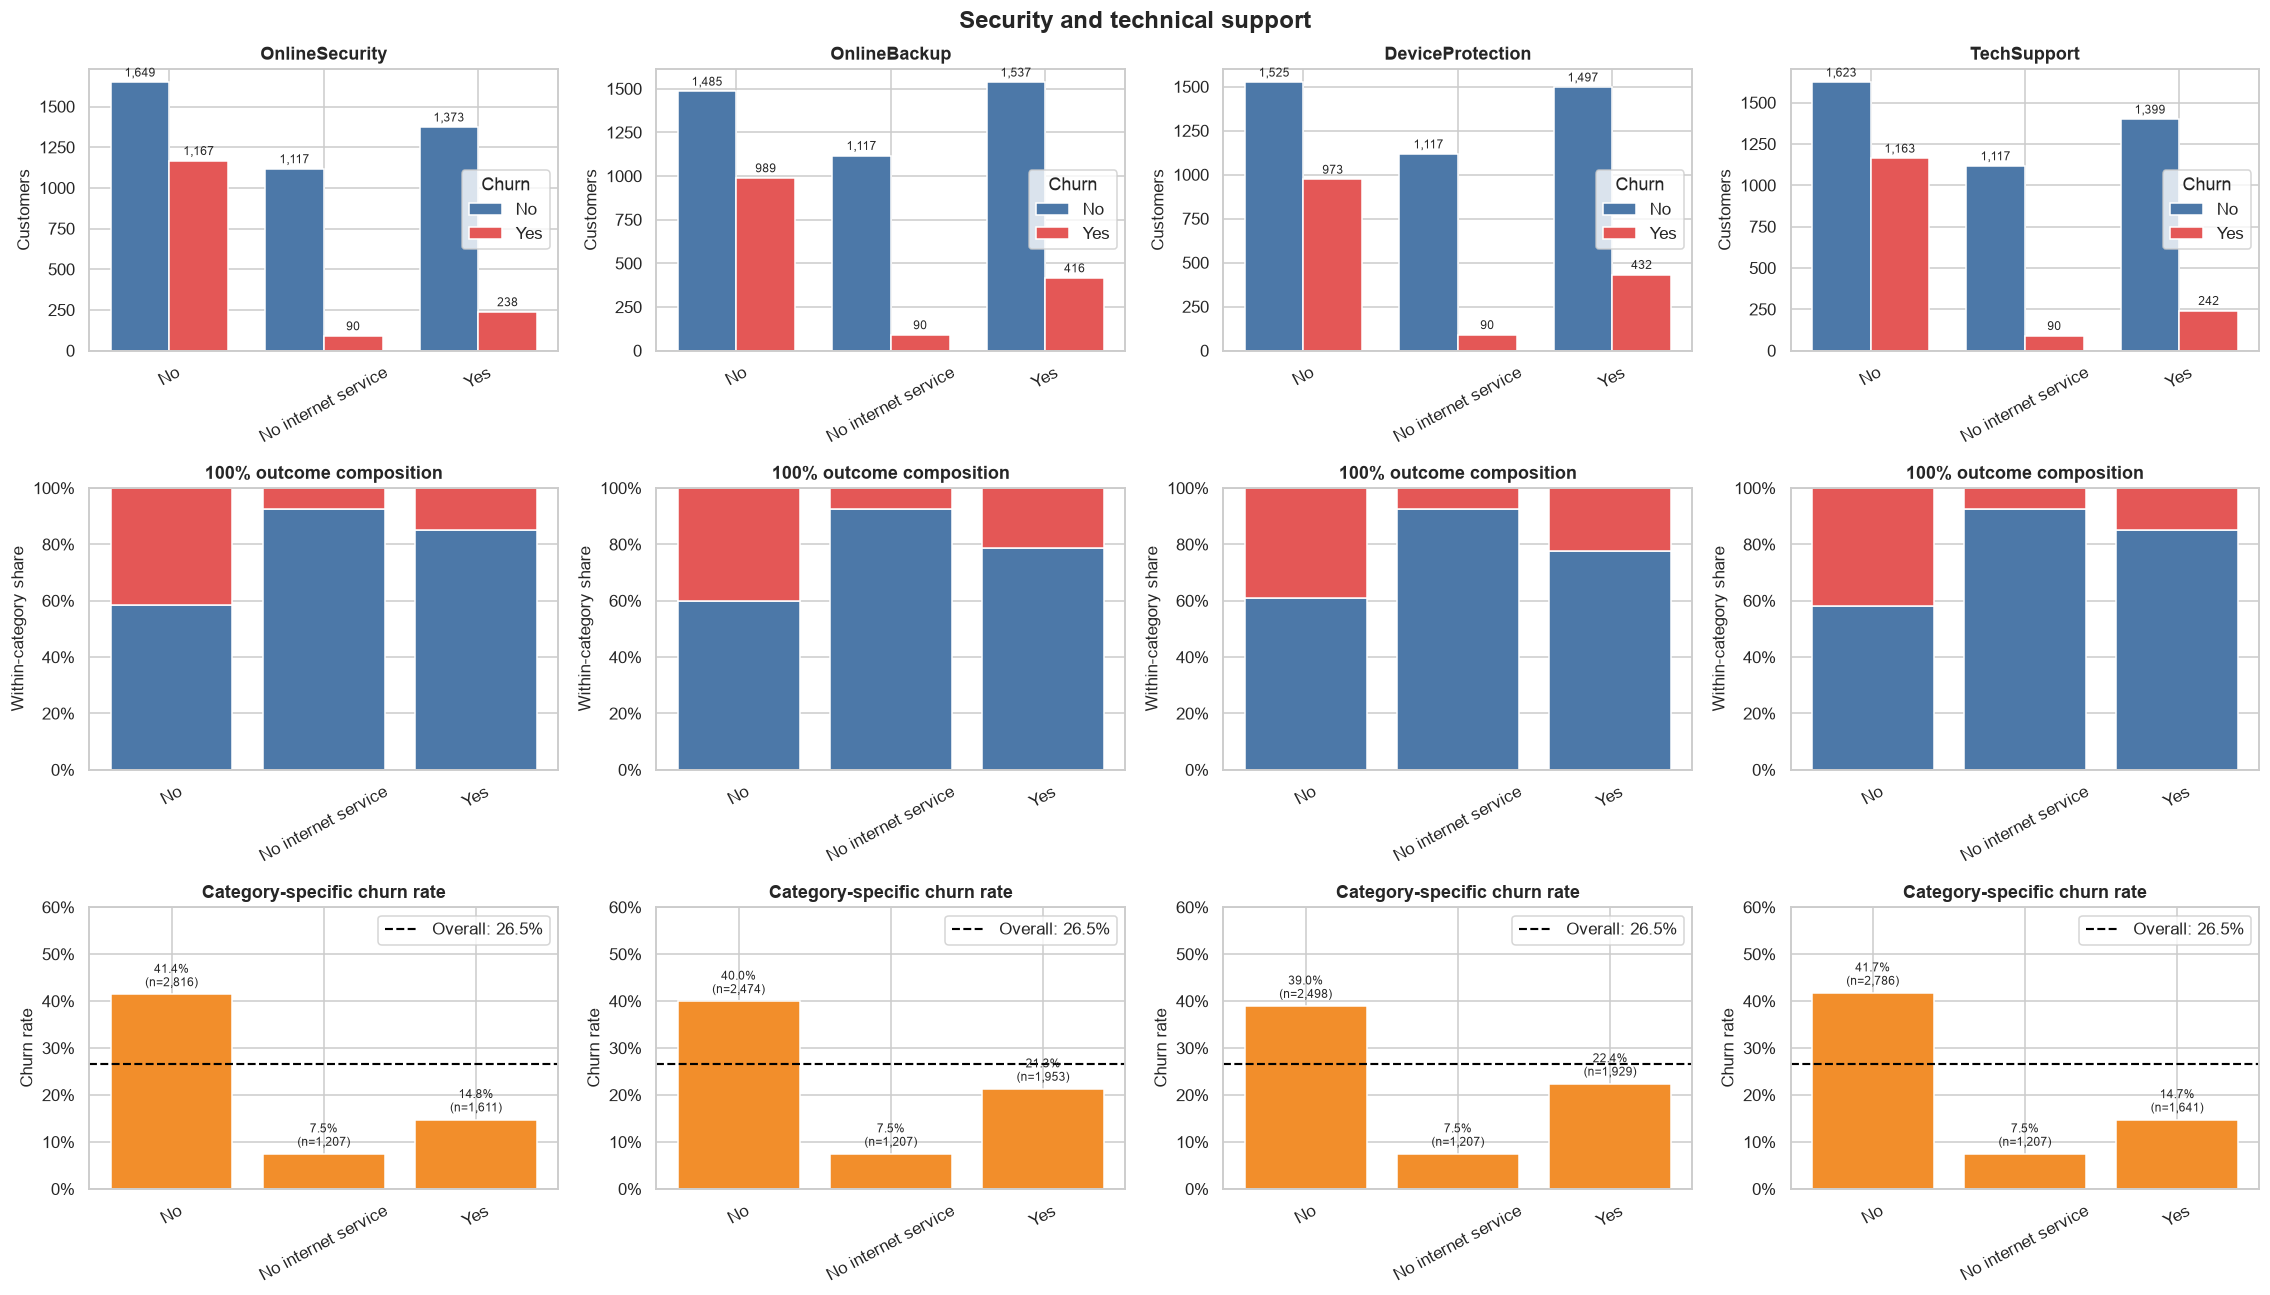

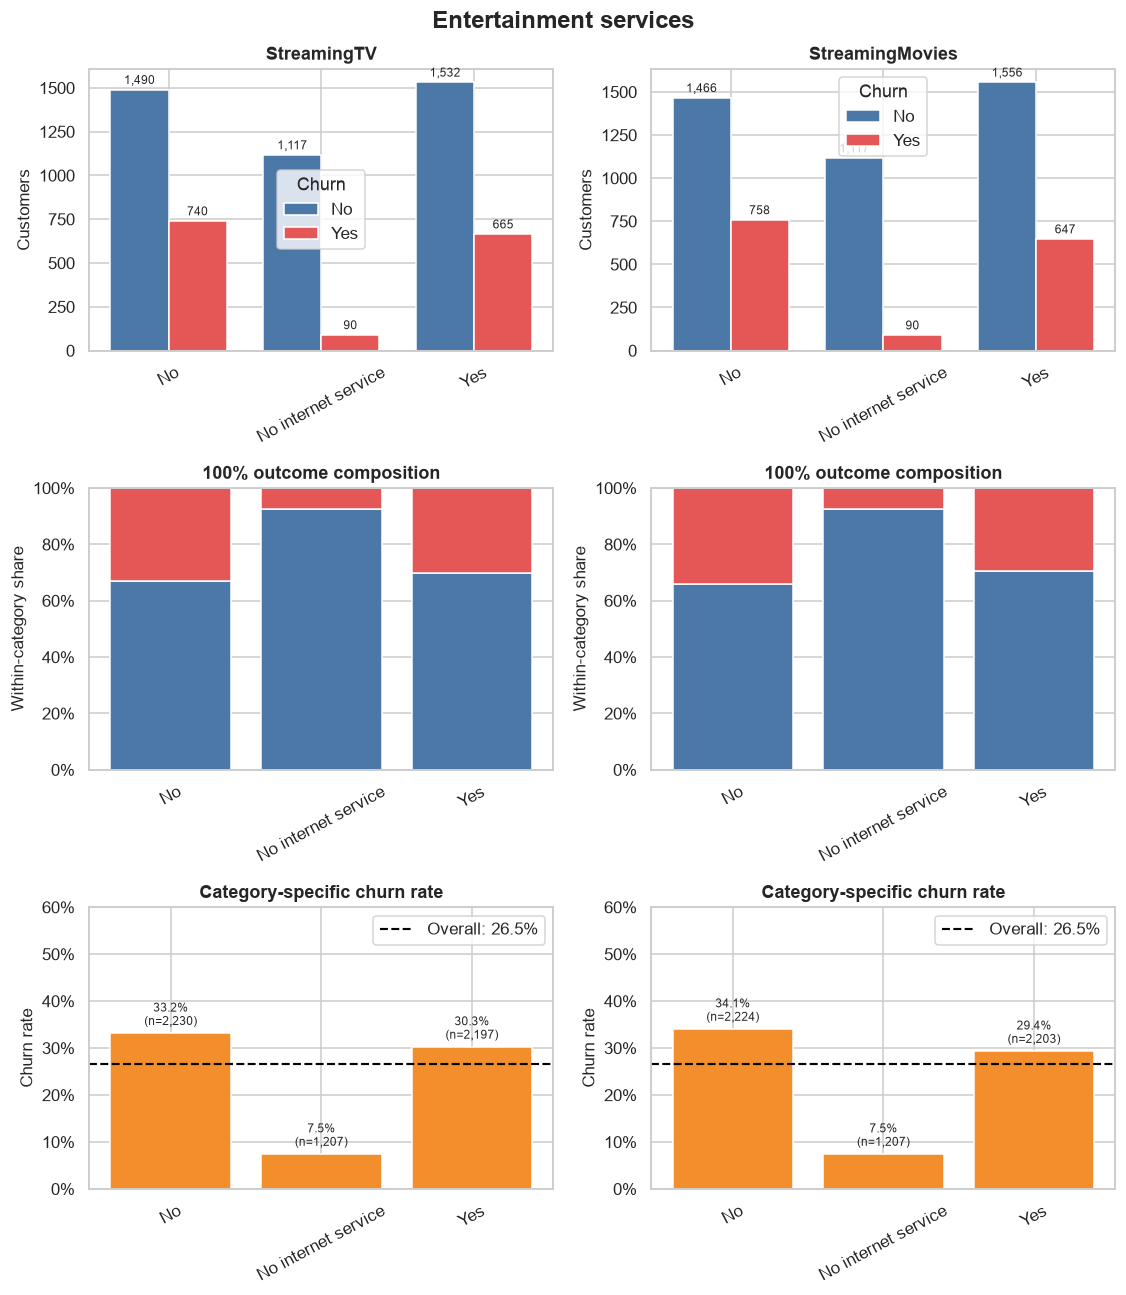

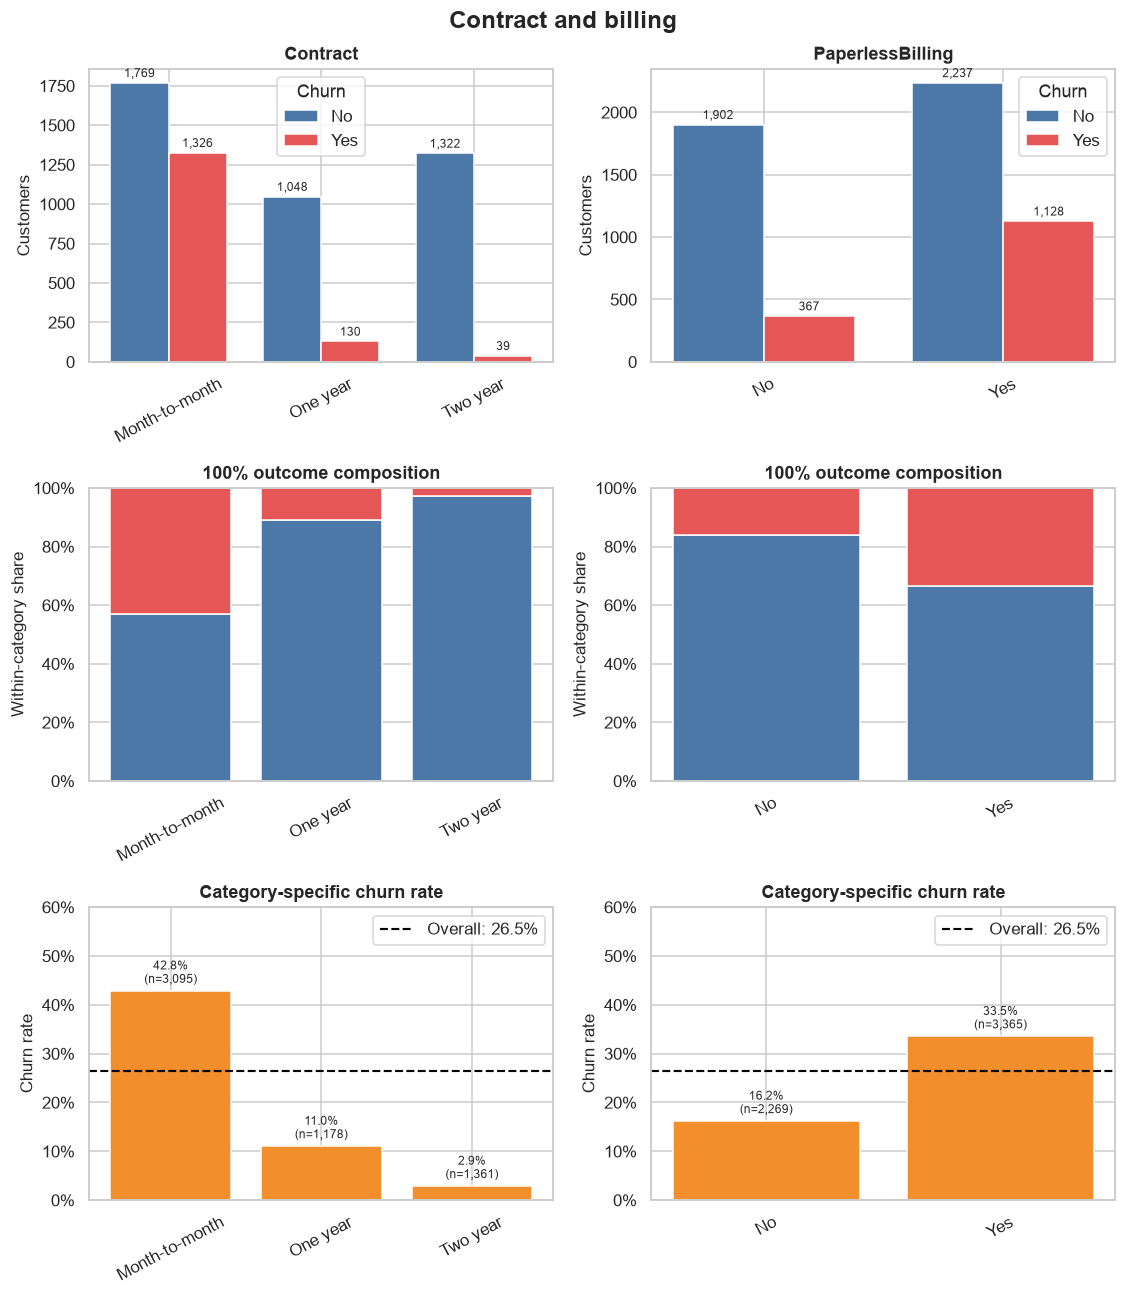

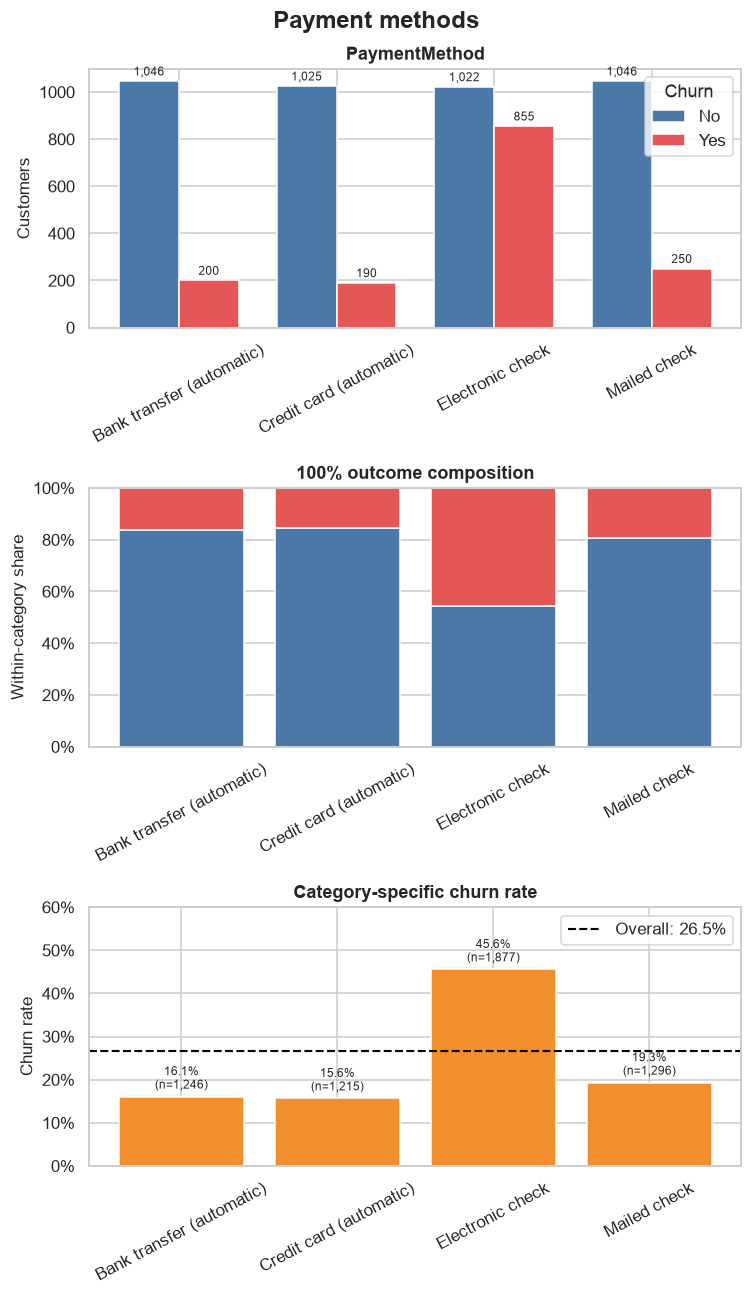

In [10]:
# ruff: noqa: E501
business_dimensions = {
    "Customer demographics": ["gender", "SeniorCitizen", "Partner", "Dependents"],
    "Phone services": ["PhoneService", "MultipleLines"],
    "Internet services": ["InternetService"],
    "Security and technical support": [
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
    ],
    "Entertainment services": ["StreamingTV", "StreamingMovies"],
    "Contract and billing": ["Contract", "PaperlessBilling"],
    "Payment methods": ["PaymentMethod"],
}

for dimension, features in business_dimensions.items():
    fig, axes = plt.subplots(
        3,
        len(features),
        figsize=(max(7, 5.2 * len(features)), 12),
        squeeze=False,
    )
    for column_index, feature in enumerate(features):
        counts = contingency_counts[feature]
        category_labels = counts.index.astype(str)
        positions = np.arange(len(counts))
        width = 0.38

        count_axis = axes[0, column_index]
        for offset, churn_class in [(-width / 2, "No"), (width / 2, "Yes")]:
            bars = count_axis.bar(
                positions + offset,
                counts[churn_class],
                width,
                label=churn_class,
                color=target_colors[churn_class],
            )
            count_axis.bar_label(bars, padding=2, fontsize=8, fmt="{:,.0f}")
        count_axis.set(title=feature, ylabel="Customers", xticks=positions, xticklabels=category_labels)
        count_axis.tick_params(axis="x", rotation=28)
        count_axis.legend(title="Churn")

        stacked_axis = axes[1, column_index]
        row_rates = row_normalized[feature]
        stacked_axis.bar(positions, row_rates["No"], color=target_colors["No"], label="No")
        stacked_axis.bar(
            positions,
            row_rates["Yes"],
            bottom=row_rates["No"],
            color=target_colors["Yes"],
            label="Yes",
        )
        stacked_axis.set(
            title="100% outcome composition",
            ylabel="Within-category share",
            ylim=(0, 1),
            xticks=positions,
            xticklabels=category_labels,
        )
        stacked_axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
        stacked_axis.tick_params(axis="x", rotation=28)

        rate_axis = axes[2, column_index]
        feature_profile = category_churn_profile.loc[category_churn_profile["feature"].eq(feature)].copy()
        bars = rate_axis.bar(
            positions,
            feature_profile["category_churn_rate"],
            color="#F28E2B",
        )
        rate_axis.axhline(
            overall_churn_rate,
            color="black",
            linestyle="--",
            linewidth=1.4,
            label=f"Overall: {overall_churn_rate:.1%}",
        )
        labels = [
            f"{rate:.1%}\n(n={count:,})"
            for rate, count in zip(
                feature_profile["category_churn_rate"],
                feature_profile["total_customers"],
                strict=True,
            )
        ]
        rate_axis.bar_label(bars, labels=labels, padding=3, fontsize=8)
        rate_axis.set(
            title="Category-specific churn rate",
            ylabel="Churn rate",
            ylim=(0, max(0.60, feature_profile["category_churn_rate"].max() * 1.25)),
            xticks=positions,
            xticklabels=category_labels,
        )
        rate_axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
        rate_axis.tick_params(axis="x", rotation=28)
        rate_axis.legend()

    fig.suptitle(dimension, fontsize=16, fontweight="bold")
    fig.tight_layout()
    plt.show()

## 3.4 Observed categorical associations

- **Commitment:** month-to-month customers show a 42.84% churn rate (1,326/3,095), while
  one-year and two-year customers show 11.04% and 2.87%. Contract may proxy commitment,
  tenure, or selection; the contrast is not an intervention effect.
- **Internet:** fibre-optic customers show 41.60% churn (1,037/2,493), compared with 18.95%
  for DSL and 7.46% for no internet. Price and service composition are plausible
  confounders.
- **Support/security:** `No` online security and `No` tech support show rates around 41%,
  while `Yes` groups are around 15%. Structural no-internet groups remain distinct and have
  the same 7.46% rate as their parent state.
- **Payment:** electronic check has the highest category rate, 45.55% (855/1,877), and
  contributes 57.19% of all churners. Automatic methods are near 16%; tenure and contract
  composition may confound this association.
- **Demographics:** senior-citizen-coded `1` shows 41.96% churn (381/908), but the larger
  `0` group produces more churners in absolute count (1,114). Gender rates are close
  (female 27.24%, male 25.86%).
- **Rate versus volume:** `PhoneService=Yes` contains 1,361 churners—the highest absolute
  volume—because 90.61% of all customers have phone service; its 26.66% rate is essentially
  the overall rate. High volume alone is not evidence of elevated category risk.

# 4. Numerical predictor versus numerical predictor

Scatter plots preserve individual observations but can suffer severe overplotting. Hexbin
plots aggregate nearby points and encode density by colour, revealing structure hidden by
overlap. Neither plot estimates a formal correlation coefficient.

- **Positive relationship:** larger $X$ tends to accompany larger $Y$.
- **Negative relationship:** larger $X$ tends to accompany smaller $Y$.
- **Nonlinearity:** the typical change is not a constant straight-line slope.
- **Heteroscedasticity:** vertical spread changes across $X$.

Accumulated charges are expected to rise with both tenure and recurring charges, so
`TotalCharges` may contain partially redundant information. It must not be assumed to equal
`tenure × MonthlyCharges`: partial billing periods, pricing changes, discounts, fees, and
the dataset's billing definition can create departures. Association does not show that one
variable causes another or that either causes churn.

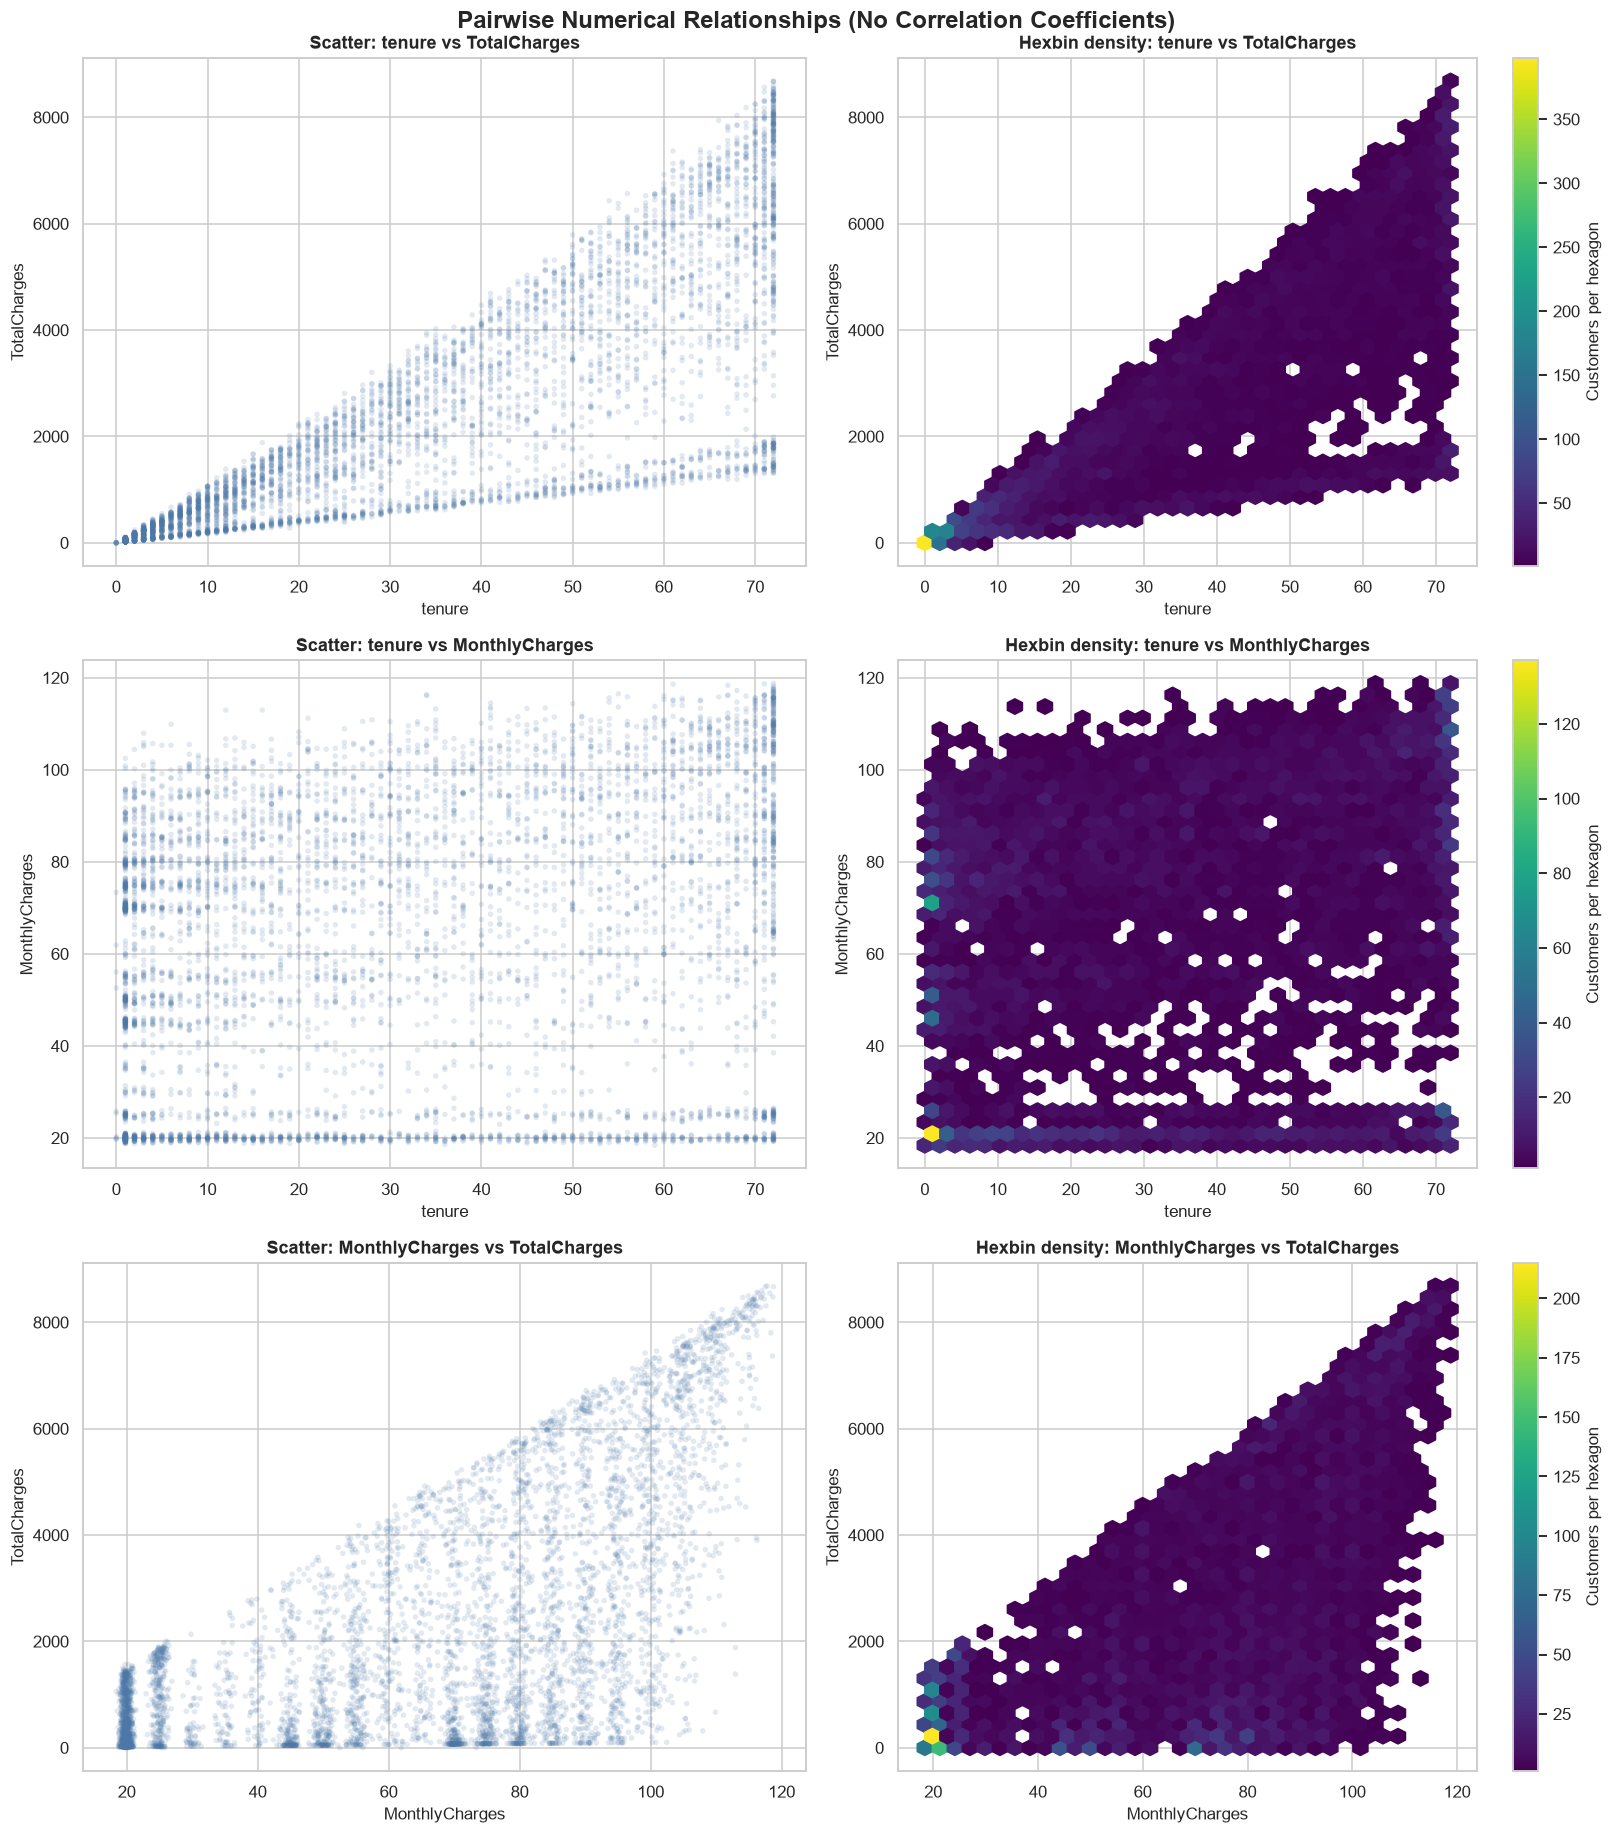

In [11]:
# ruff: noqa: E501
numerical_pairs = [
    ("tenure", "TotalCharges"),
    ("tenure", "MonthlyCharges"),
    ("MonthlyCharges", "TotalCharges"),
]

fig, axes = plt.subplots(3, 2, figsize=(15, 17))
for row, (x_feature, y_feature) in enumerate(numerical_pairs):
    scatter_axis = axes[row, 0]
    hex_axis = axes[row, 1]
    scatter_axis.scatter(
        df[x_feature],
        df[y_feature],
        alpha=0.16,
        s=13,
        color="#4C78A8",
        edgecolors="none",
    )
    scatter_axis.set(
        title=f"Scatter: {x_feature} vs {y_feature}",
        xlabel=x_feature,
        ylabel=y_feature,
    )
    hexbin = hex_axis.hexbin(
        df[x_feature],
        df[y_feature],
        gridsize=35,
        mincnt=1,
        cmap="viridis",
    )
    hex_axis.set(
        title=f"Hexbin density: {x_feature} vs {y_feature}",
        xlabel=x_feature,
        ylabel=y_feature,
    )
    fig.colorbar(hexbin, ax=hex_axis, label="Customers per hexagon")

fig.suptitle("Pairwise Numerical Relationships (No Correlation Coefficients)", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

### Observed numerical-pair patterns

- **Tenure–TotalCharges:** a strong positive, fan-shaped relationship is visible. Low
  tenure constrains accumulated totals, while high tenure permits a much wider range. The
  increasing spread is heteroscedastic and reflects different recurring prices and billing
  histories.
- **Tenure–MonthlyCharges:** no simple monotonic line dominates. Customers at many tenure
  levels occupy both lower and higher price bands, suggesting subscription configuration
  varies throughout the lifecycle.
- **MonthlyCharges–TotalCharges:** the upper envelope rises with monthly charge, but total
  charges remain highly dispersed at a given monthly price because tenure and billing
  history vary. This is a positive but structurally confounded association.

These visual relationships motivate later formal correlation and multivariate work; no
coefficient is calculated here.

# 5. Selected categorical–numerical relationships

Group-wise statistics and violin/box distributions describe how a numerical feature varies
across business categories. For group $c$, summaries estimate the empirical distribution
$X\mid Category=c$. They do not establish why the distributions differ.

Potential confounding matters when two predictors are both associated with an outcome. For
example, if contract groups have different tenure distributions, an unadjusted
contract–churn difference may partly reflect lifecycle composition. Identifying a possible
confounder is not the same as controlling for it; no three-variable stratification,
interaction, regression, or causal adjustment is performed in this step.

In [12]:
# ruff: noqa: E501
categorical_numerical_pairs = [
    ("Contract", "tenure"),
    ("Contract", "MonthlyCharges"),
    ("InternetService", "MonthlyCharges"),
    ("InternetService", "TotalCharges"),
    ("PaymentMethod", "tenure"),
]

categorical_numerical_rows = []
for categorical_feature, numerical_feature in categorical_numerical_pairs:
    for category, group in df.groupby(categorical_feature, dropna=False):
        values = group[numerical_feature]
        categorical_numerical_rows.append({
            "categorical_feature": categorical_feature,
            "numerical_feature": numerical_feature,
            "category": str(category),
            "count": len(values),
            "mean": values.mean(),
            "median": values.median(),
            "standard_deviation": values.std(ddof=1),
            "q1": values.quantile(0.25),
            "q3": values.quantile(0.75),
            "IQR": values.quantile(0.75) - values.quantile(0.25),
        })

categorical_numerical_profile = pd.DataFrame(categorical_numerical_rows)
display(categorical_numerical_profile)

,categorical_feature,numerical_feature,category,count,mean,median,standard_deviation,q1,q3,IQR
0,Contract,tenure,Month-to-month,3095,18.115,12.000,17.723,3.000,29.000,26.000
1,Contract,tenure,One year,1178,41.523,43.000,19.378,26.000,58.000,32.000
2,Contract,tenure,Two year,1361,56.780,64.000,18.225,48.000,71.000,23.000
3,Contract,MonthlyCharges,Month-to-month,3095,66.755,73.750,26.799,46.325,88.975,42.650
4,Contract,MonthlyCharges,One year,1178,64.735,67.600,31.713,27.625,94.737,67.112
5,Contract,MonthlyCharges,Two year,1361,61.373,64.900,34.771,24.050,90.800,66.750
6,InternetService,MonthlyCharges,DSL,1934,58.351,56.350,16.095,46.350,70.087,23.737
7,InternetService,MonthlyCharges,Fiber optic,2493,91.517,91.850,12.667,80.500,101.100,20.600
8,InternetService,MonthlyCharges,No,1207,21.037,20.100,2.152,19.700,20.850,1.150
9,InternetService,TotalCharges,DSL,1934,"2,117.705","1,604.525","1,873.634",436.100,"3,485.850","3,049.750"


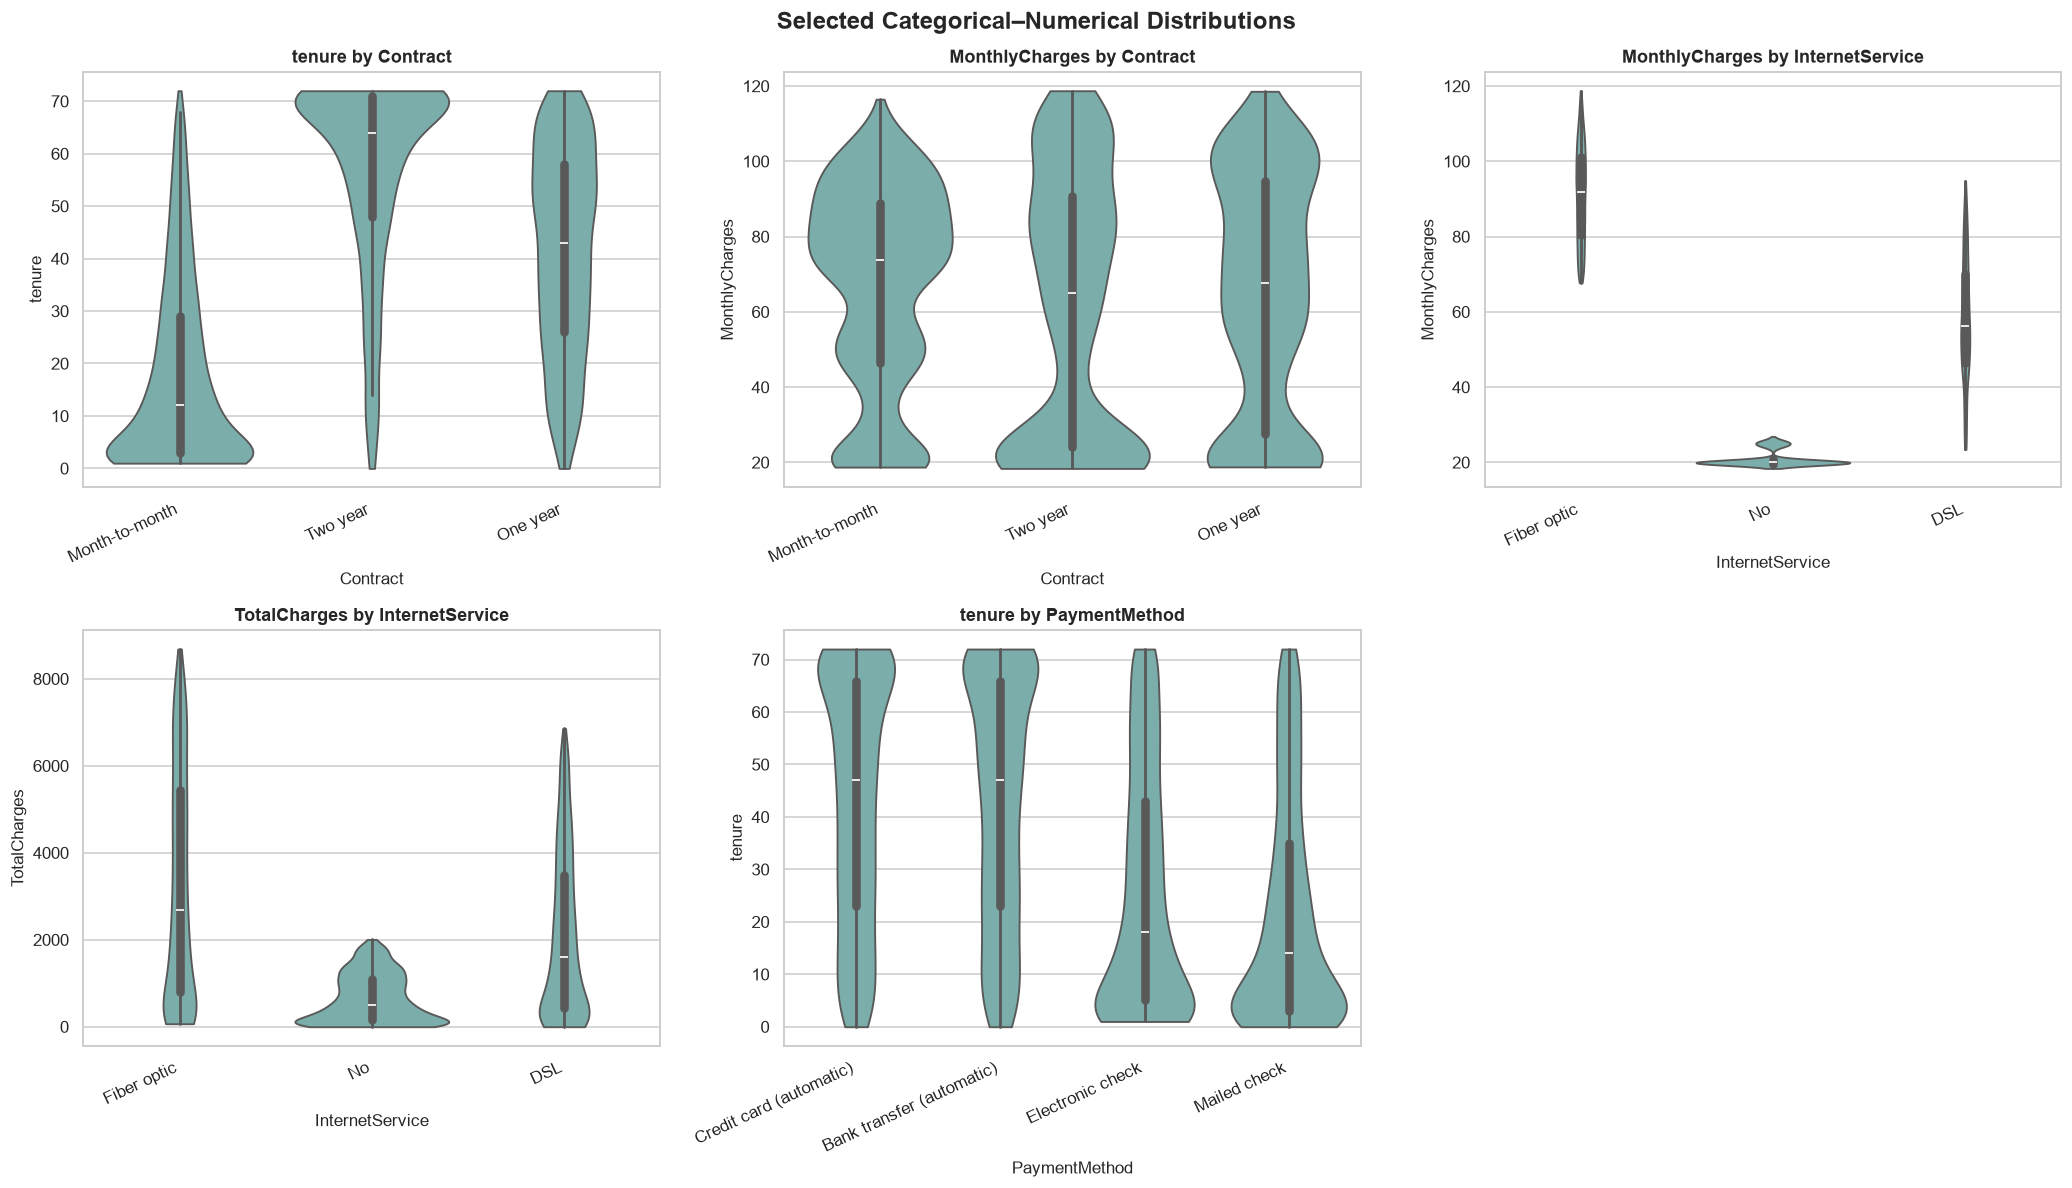

In [13]:
# ruff: noqa: E501
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
for axis, (categorical_feature, numerical_feature) in zip(
    axes.flat,
    categorical_numerical_pairs,
    strict=False,
):
    sns.violinplot(
        data=df,
        x=categorical_feature,
        y=numerical_feature,
        inner="box",
        cut=0,
        color="#72B7B2",
        ax=axis,
    )
    axis.set(
        title=f"{numerical_feature} by {categorical_feature}",
        xlabel=categorical_feature,
        ylabel=numerical_feature,
    )
    axis.tick_params(axis="x", rotation=25)
    for label in axis.get_xticklabels():
        label.set_horizontalalignment("right")
for axis in axes.flat[len(categorical_numerical_pairs):]:
    axis.set_visible(False)

fig.suptitle("Selected Categorical–Numerical Distributions", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

### Observed categorical–numerical patterns and confounding questions

- Median tenure rises from **12 months** for month-to-month contracts to **43** for one-year
  and **64** for two-year contracts. Contract commitment and lifecycle are therefore
  intertwined in this sample.
- Median monthly charges are **73.75** for month-to-month, **67.60** for one-year, and
  **64.90** for two-year contracts. Price mix may contribute to unadjusted contract–churn
  patterns.
- Internet service strongly separates monthly charges: median **20.10** for no internet,
  **56.35** for DSL, and **91.85** for fibre optic. The higher fibre churn rate cannot be
  interpreted independently of price and service composition.
- Median total charges are **507.40** for no internet, **1,604.53** for DSL, and
  **2,673.45** for fibre. Both tenure and monthly price can contribute.
- Median tenure is **14 months** for mailed check, **18** for electronic check, and **47**
  for both automatic payment methods. Payment preference may proxy lifecycle or contract
  maturity, so its observed churn rate is not a standalone causal effect.

# 6. Business findings and interpretation boundaries

## Evidence-based observations

- **Lifecycle:** churned customers are concentrated at shorter tenure, but early-tenure and
  long-tenure outcome distributions overlap.
- **Commitment:** month-to-month customers have both the highest contract churn rate and
  highest contract churn volume. Longer contracts coincide with much longer tenure, a
  likely confounding structure.
- **Charges:** churned customers have higher monthly but lower accumulated charges on
  average. Shorter tenure can reconcile those directions.
- **Internet:** fibre customers show elevated observed churn and higher charges. Service
  quality, price, tenure, and plan composition are not separately identified.
- **Support/security:** customers without online security or tech support show higher
  observed churn rates than adopters, but selection and service eligibility remain
  plausible explanations.
- **Payment:** electronic check has the highest category churn rate; automatic-payment
  customers are much longer-tenured on average.
- **Demographics:** the senior-citizen-coded group has a higher observed rate, while gender
  rates are close. Fairness and subgroup reliability require dedicated later analysis.
- **Rate versus volume:** phone service produces the largest churn volume but no meaningful
  rate elevation; electronic check has both an elevated rate and substantial volume.

## Interpretation boundaries

Observed association describes co-occurrence. Statistical significance would require an
inferential procedure, predictive importance requires validated models, and causation
requires a defensible causal design or intervention evidence. This dataset contains no
randomized retention treatment or intervention outcome, so no action is claimed to be
proven effective.

## Questions for later stages

1. Do contract differences persist after accounting for tenure and price?
2. Does fibre-optic churn remain elevated within comparable charge and tenure groups?
3. How stable are category rates across validation folds and time-like splits?
4. Which numerical relationships are monotonic, nonlinear, or redundant under formal
   association measures?
5. Do calibrated multivariate models preserve subgroup performance and decision utility?

# 7. Interview questions with speakable answers

### 1. What is the difference between $P(Churn\mid Category)$ and $P(Category\mid Churn)$?

**Speakable answer:** “The first divides churners in a category by everyone in that
category, so it is the category-specific churn rate. The second divides churners from that
category by all churners, so it describes churn volume composition. A large category can
have a normal rate but dominate churn volume. The denominators and business questions are
different.”

### 2. Why can month-to-month contract appear strongly associated with churn without being causal?

**Speakable answer:** “Month-to-month customers have a 42.84% observed churn rate, but
their median tenure is only 12 months versus 64 for two-year customers. Contract choice,
tenure, price, service mix, and customer preferences may be jointly related. Bivariate
association does not isolate the effect of changing a contract, so I would call tenure a
potential confounder and avoid causal language.”

### 3. Why use normalized histograms for churn groups?

**Speakable answer:** “There are many more retained than churned customers. Raw histogram
counts would mainly reflect that size difference. Normalizing each group separately lets
me compare distribution shape and concentration. It still does not test significance, and
overlap shows that no single numerical cutoff perfectly separates the classes.”

### 4. What does the tenure–TotalCharges hexbin plot add beyond a scatter plot?

**Speakable answer:** “Thousands of scatter points overlap, hiding dense regions. Hexbin
aggregates local counts and reveals the fan-shaped positive relationship and changing
variance. It also shows why TotalCharges may be partly redundant with tenure while not
being an exact product. I would defer formal correlation and multivariate redundancy tests
to the designated later step.”

# 8. Verification and remaining limitations

## Limitations

- This is a static development sample without timestamps or intervention outcomes.
- Category rates can reflect confounding and selection; no adjustment is performed.
- KDE, violin, histogram, and hexbin appearances depend on smoothing or binning choices.
- No p-values, confidence intervals, correlation coefficients, association statistics,
  multivariate interactions, predictive importance, or causal effects are calculated.
- Currency, billing adjustments, and plan histories are undocumented.

The final audit confirms source scope, row preservation, and prior-notebook hashes.

In [14]:
# ruff: noqa: E501
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for block in iter(lambda: file.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


previous_notebook_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
}
for notebook_name, expected_hash in previous_notebook_hashes.items():
    actual_hash = sha256(PROJECT_ROOT / "notebooks" / notebook_name)
    assert actual_hash == expected_hash, f"Previous notebook changed: {notebook_name}"
    print(f"Verified unchanged: {notebook_name} ({actual_hash})")

assert development_path == (PROJECT_ROOT / "data/processed/development.parquet").resolve()
assert df.shape == (5_634, 21)
assert df[target_column].value_counts().to_dict() == {"No": 4_139, "Yes": 1_495}
assert len(category_churn_profile) == sum(df[feature].nunique() for feature in categorical_features)

print("Leakage audit passed: one configured development Parquet input was loaded.")
print("No rows, outliers, categories, features, or target labels were modified.")
print("No hypothesis test, formal correlation/association coefficient, multivariate interaction, or model was run.")

Verified unchanged: 01_exploratory_data_analysis.ipynb (970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b)
Verified unchanged: 02_univariate_analysis.ipynb (0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a)
Leakage audit passed: one configured development Parquet input was loaded.
No rows, outliers, categories, features, or target labels were modified.
No hypothesis test, formal correlation/association coefficient, multivariate interaction, or model was run.
